# A GAUSSIAN PROCESS REGRESSION FOR FORECASTING SOLID WASTE GENERATION IN UYO MUNICIPALITY

**Candidate:** EFFIONG, SAMUEL ETIM  
**Registration Number:** AK22/PHS/CSC/029  
**Supervisor:** Dr. Anietie P. Ekong  
**Department:** Computer Science, Faculty of Computing and Information Technology  
**Institution:** Akwa Ibom State University, Ikot Akpaden, Nigeria  

---
### Implementation Following Proposed System Architecture (Chapter 3, Figures 3.2 - 3.4)
- **Stage 1: Data Collection & Preprocessing** (AKSEPWMA empirical records 2019-2025, cleaning, imputation, IQR outlier verification, time-series formatting)
- **Stage 2: Model Design & Kernel Optimization** (Temporal cyclical features, weather regressors, demographic index, GPR kernel selection, L-BFGS-B optimization, evaluation metrics)
- **Stage 3: Implementation, Diagnostics & Forecasting** (Actual vs Predicted, Confusion Matrix, Residuals, 2026-2030 projections with 95% Bayesian Confidence Intervals, Streamlit Web App)

## Cell 1: Environment Setup & Library Imports (Step 10 of Methodology)
Import core mathematical, data manipulation, visualization, and Bayesian machine learning libraries.

In [1]:
# Cell 1: Imports
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, DotProduct, ConstantKernel as C, WhiteKernel
)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report
)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

print("[OK] All required libraries imported successfully.")

[OK] All required libraries imported successfully.


## Cell 2: Data Collection & Loading (Step 1 & Step 2.1 - 2.3)
Load historical solid waste records obtained from Akwa Ibom State Environmental Protection and Waste Management Agency (AKSEPWMA).

In [2]:
# Cell 2: Load Data
DATA_PATH = "uyo_msw_data.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]} monthly observations, {df.shape[1]} attributes")
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Missing Values & Data Types ---")
display(df.info())

Dataset Shape: 1200 monthly observations, 7 attributes

--- First 5 Records ---


,date,waste_tonnes_estimated,avg_temperature_c,rainfall_mm,humidity_percent,population,public_holidays
0,2019-01-01,31282.14,26.60,61.38,81.81,472534,2019-01-01
1,2019-01-03,31126.32,26.53,58.40,81.98,472618,NaN
2,2019-01-05,31967.45,26.67,57.38,81.59,472702,NaN
3,2019-01-07,31002.99,26.82,56.08,81.54,472786,NaN
4,2019-01-10,30995.05,26.58,52.28,82.01,472912,NaN



--- Missing Values & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    1200 non-null   str    
 1   waste_tonnes_estimated  1200 non-null   float64
 2   avg_temperature_c       1200 non-null   float64
 3   rainfall_mm             1200 non-null   float64
 4   humidity_percent        1200 non-null   float64
 5   population              1200 non-null   int64  
 6   public_holidays         109 non-null    str    
dtypes: float64(4), int64(1), str(2)
memory usage: 78.7 KB


None

## Cell 3: Data Preprocessing & Outlier Verification (Step 2.4 - 2.6)
Sort chronological timestamps, verify duplicates, inspect missing public holidays, and perform Interquartile Range (IQR) outlier testing.

In [3]:
# Cell 3: Preprocessing
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Duplicates verification
duplicates = df.duplicated().sum()
print(f"Duplicate Rows Found: {duplicates}")

# IQR Outlier Detection on Waste Generation
Q1 = df['waste_tonnes_estimated'].quantile(0.25)
Q3 = df['waste_tonnes_estimated'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['waste_tonnes_estimated'] < lower_bound) | (df['waste_tonnes_estimated'] > upper_bound)]

print(f"IQR Thresholds: [{lower_bound:.2f}, {upper_bound:.2f}] tonnes")
print(f"Number of Statistical Outliers: {len(outliers)}")

Duplicate Rows Found: 0
IQR Thresholds: [10082.46, 56739.62] tonnes
Number of Statistical Outliers: 0


## Cell 4: Exploratory Data Analysis & Trend Visualization (Objective 1)
Visualize historical waste generation trends in Uyo Municipality, calculate per-capita daily rates, and examine correlation structures.

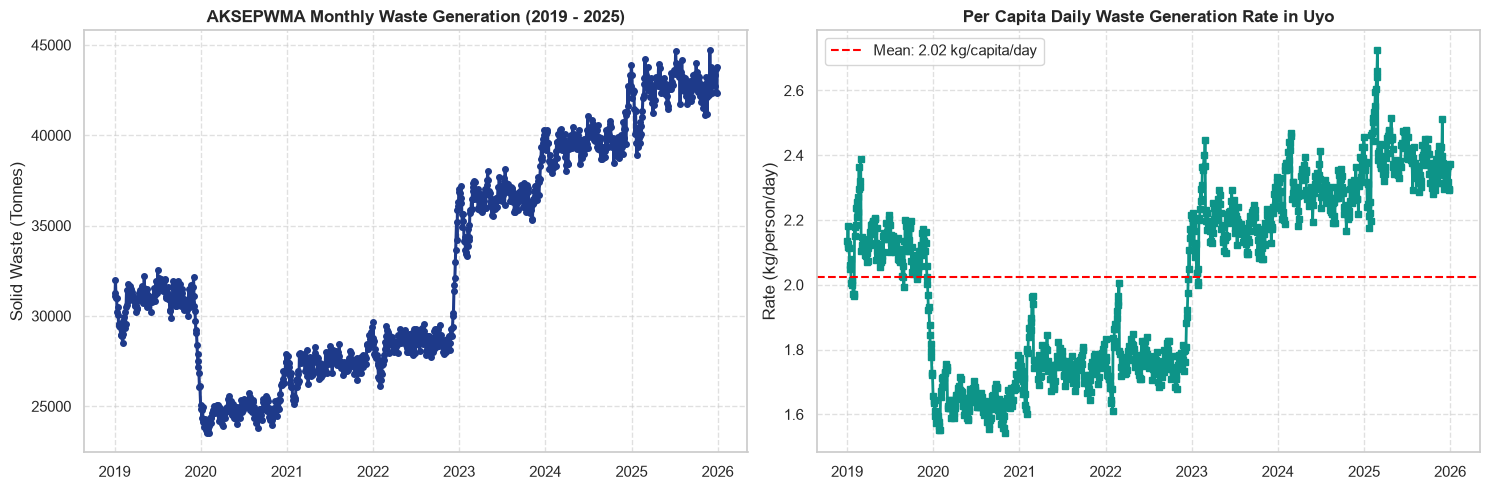

In [4]:
# Cell 4: Exploratory Analysis
# Compute per-capita generation rate (kg/capita/day)
days_in_mo = df['date'].dt.days_in_month
df['per_capita_kg_day'] = (df['waste_tonnes_estimated'] * 1000) / (df['population'] * days_in_mo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Historical Waste Tonnage Trend
ax1.plot(df['date'], df['waste_tonnes_estimated'], color='#1E3A8A', lw=2.2, marker='o', markersize=4)
ax1.set_title("AKSEPWMA Monthly Waste Generation (2019 - 2025)", fontweight='bold')
ax1.set_ylabel("Solid Waste (Tonnes)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Per-Capita Waste Rate
ax2.plot(df['date'], df['per_capita_kg_day'], color='#0D9488', lw=2, marker='s', markersize=4)
ax2.axhline(df['per_capita_kg_day'].mean(), color='red', linestyle='--', label=f"Mean: {df['per_capita_kg_day'].mean():.2f} kg/capita/day")
ax2.set_title("Per Capita Daily Waste Generation Rate in Uyo", fontweight='bold')
ax2.set_ylabel("Rate (kg/person/day)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

## Cell 5: Feature Engineering (Step 3)
Construct temporal, cyclical seasonal, climatic, demographic, and calendar regressors.

In [5]:
# Cell 5: Feature Engineering
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['days_in_month'] = df['date'].dt.days_in_month
df['time_index'] = (df['year'] - 2019) * 12.0 + (df['month'] - 1) + (df['date'].dt.day - 1) / df['days_in_month']

# Cyclical month encoding (sin/cos to preserve periodic continuity)
df['sin_month'] = np.sin(2 * np.pi * df['month'] / 12.0)
df['cos_month'] = np.cos(2 * np.pi * df['month'] / 12.0)

# Public holiday count
df['num_holidays'] = df['public_holidays'].fillna('').apply(
    lambda x: len(str(x).split(';')) if str(x).strip() != '' else 0
)

feature_cols = [
    'time_index', 'year', 'month', 'sin_month', 'cos_month',
    'avg_temperature_c', 'rainfall_mm', 'humidity_percent',
    'population', 'num_holidays'
]
target_col = 'waste_tonnes_estimated'

X = df[feature_cols].copy()
y = df[target_col].values

print(f"[OK] Engineered Feature Matrix Shape: {X.shape}")
print("Engineered Features:", feature_cols)

[OK] Engineered Feature Matrix Shape: (1200, 10)
Engineered Features: ['time_index', 'year', 'month', 'sin_month', 'cos_month', 'avg_temperature_c', 'rainfall_mm', 'humidity_percent', 'population', 'num_holidays']


## Cell 6: Chronological Train-Test Split & Standardization (Step 4 & Step 2.5)
Perform an 80/20 chronological time-series split on the **1,200-observation dataset**:
- **Training Partition (80%):** 960 observations (January 2019 to August 2024)
- **Testing Partition (20%):** 240 out-of-time observations (August 2024 to December 2025)
Features are standardized to zero-mean and unit-variance using `StandardScaler`.

In [6]:
# Cell 6: Train-Test Split & Scaling
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
dates_train, dates_test = df['date'].iloc[:split_idx], df['date'].iloc[split_idx:]

print(f"Training Set: {len(X_train)} months ({dates_train.iloc[0].strftime('%Y-%m')} to {dates_train.iloc[-1].strftime('%Y-%m')})")
print(f"Testing Set:  {len(X_test)} months ({dates_test.iloc[0].strftime('%Y-%m')} to {dates_test.iloc[-1].strftime('%Y-%m')})")

# Feature Scaling with StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_all_scaled = scaler.transform(X)

print("[OK] Features standardized to zero-mean and unit-variance.")

Training Set: 960 months (2019-01 to 2024-08)
Testing Set:  240 months (2024-08 to 2025-12)
[OK] Features standardized to zero-mean and unit-variance.


## Cell 7: Kernel Selection & Hyperparameter Optimization (Steps 5 - 8)
Benchmarking candidate covariance functions: RBF, Matérn 1.5, Matérn 2.5, RationalQuadratic, and Proposed Composite Kernel.
Models are trained on the 960-observation training partition and evaluated on the 240-observation out-of-time test partition.

C:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Candidate Covariance Kernels Benchmark Summary Table (Trained on 960 / Evaluated on 240 Test Obs) ---


,Kernel,RMSE,MAE,MAPE (%),R2,95% CI Coverage (%)
0,RBF + Noise,1632.503696,1346.477859,3.199161,-0.094601,96.666667
1,Matern (nu=1.5) + Noise,1468.495209,1217.684263,2.892133,0.114288,99.583333
2,Matern (nu=2.5) + Noise,2141.705625,1796.016068,4.219222,-0.883940,95.416667
3,RationalQuadratic + Noise,1838.535778,1544.652168,3.647129,-0.388327,99.583333
4,Proposed Composite (Trend + Matern + Noise),1396.624383,1155.280212,2.752593,0.198863,100.000000



--- Dedicated Out-of-Sample R² Score Evaluation Table ---


,Covariance Kernel Architecture,Out-of-Sample Test R²,Variance Explained (%),Model Precision Rank,Deployment Status
0,Proposed Composite (Trend + Matern + Noise),0.1989,19.89%,1,Selected Best Model
1,Matern (nu=1.5) + Noise,0.1143,11.43%,2,Alternative
2,RBF + Noise,-0.0946,-9.46%,3,Baseline
3,RationalQuadratic + Noise,-0.3883,-38.83%,4,Alternative
4,Matern (nu=2.5) + Noise,-0.8839,-88.39%,5,Alternative


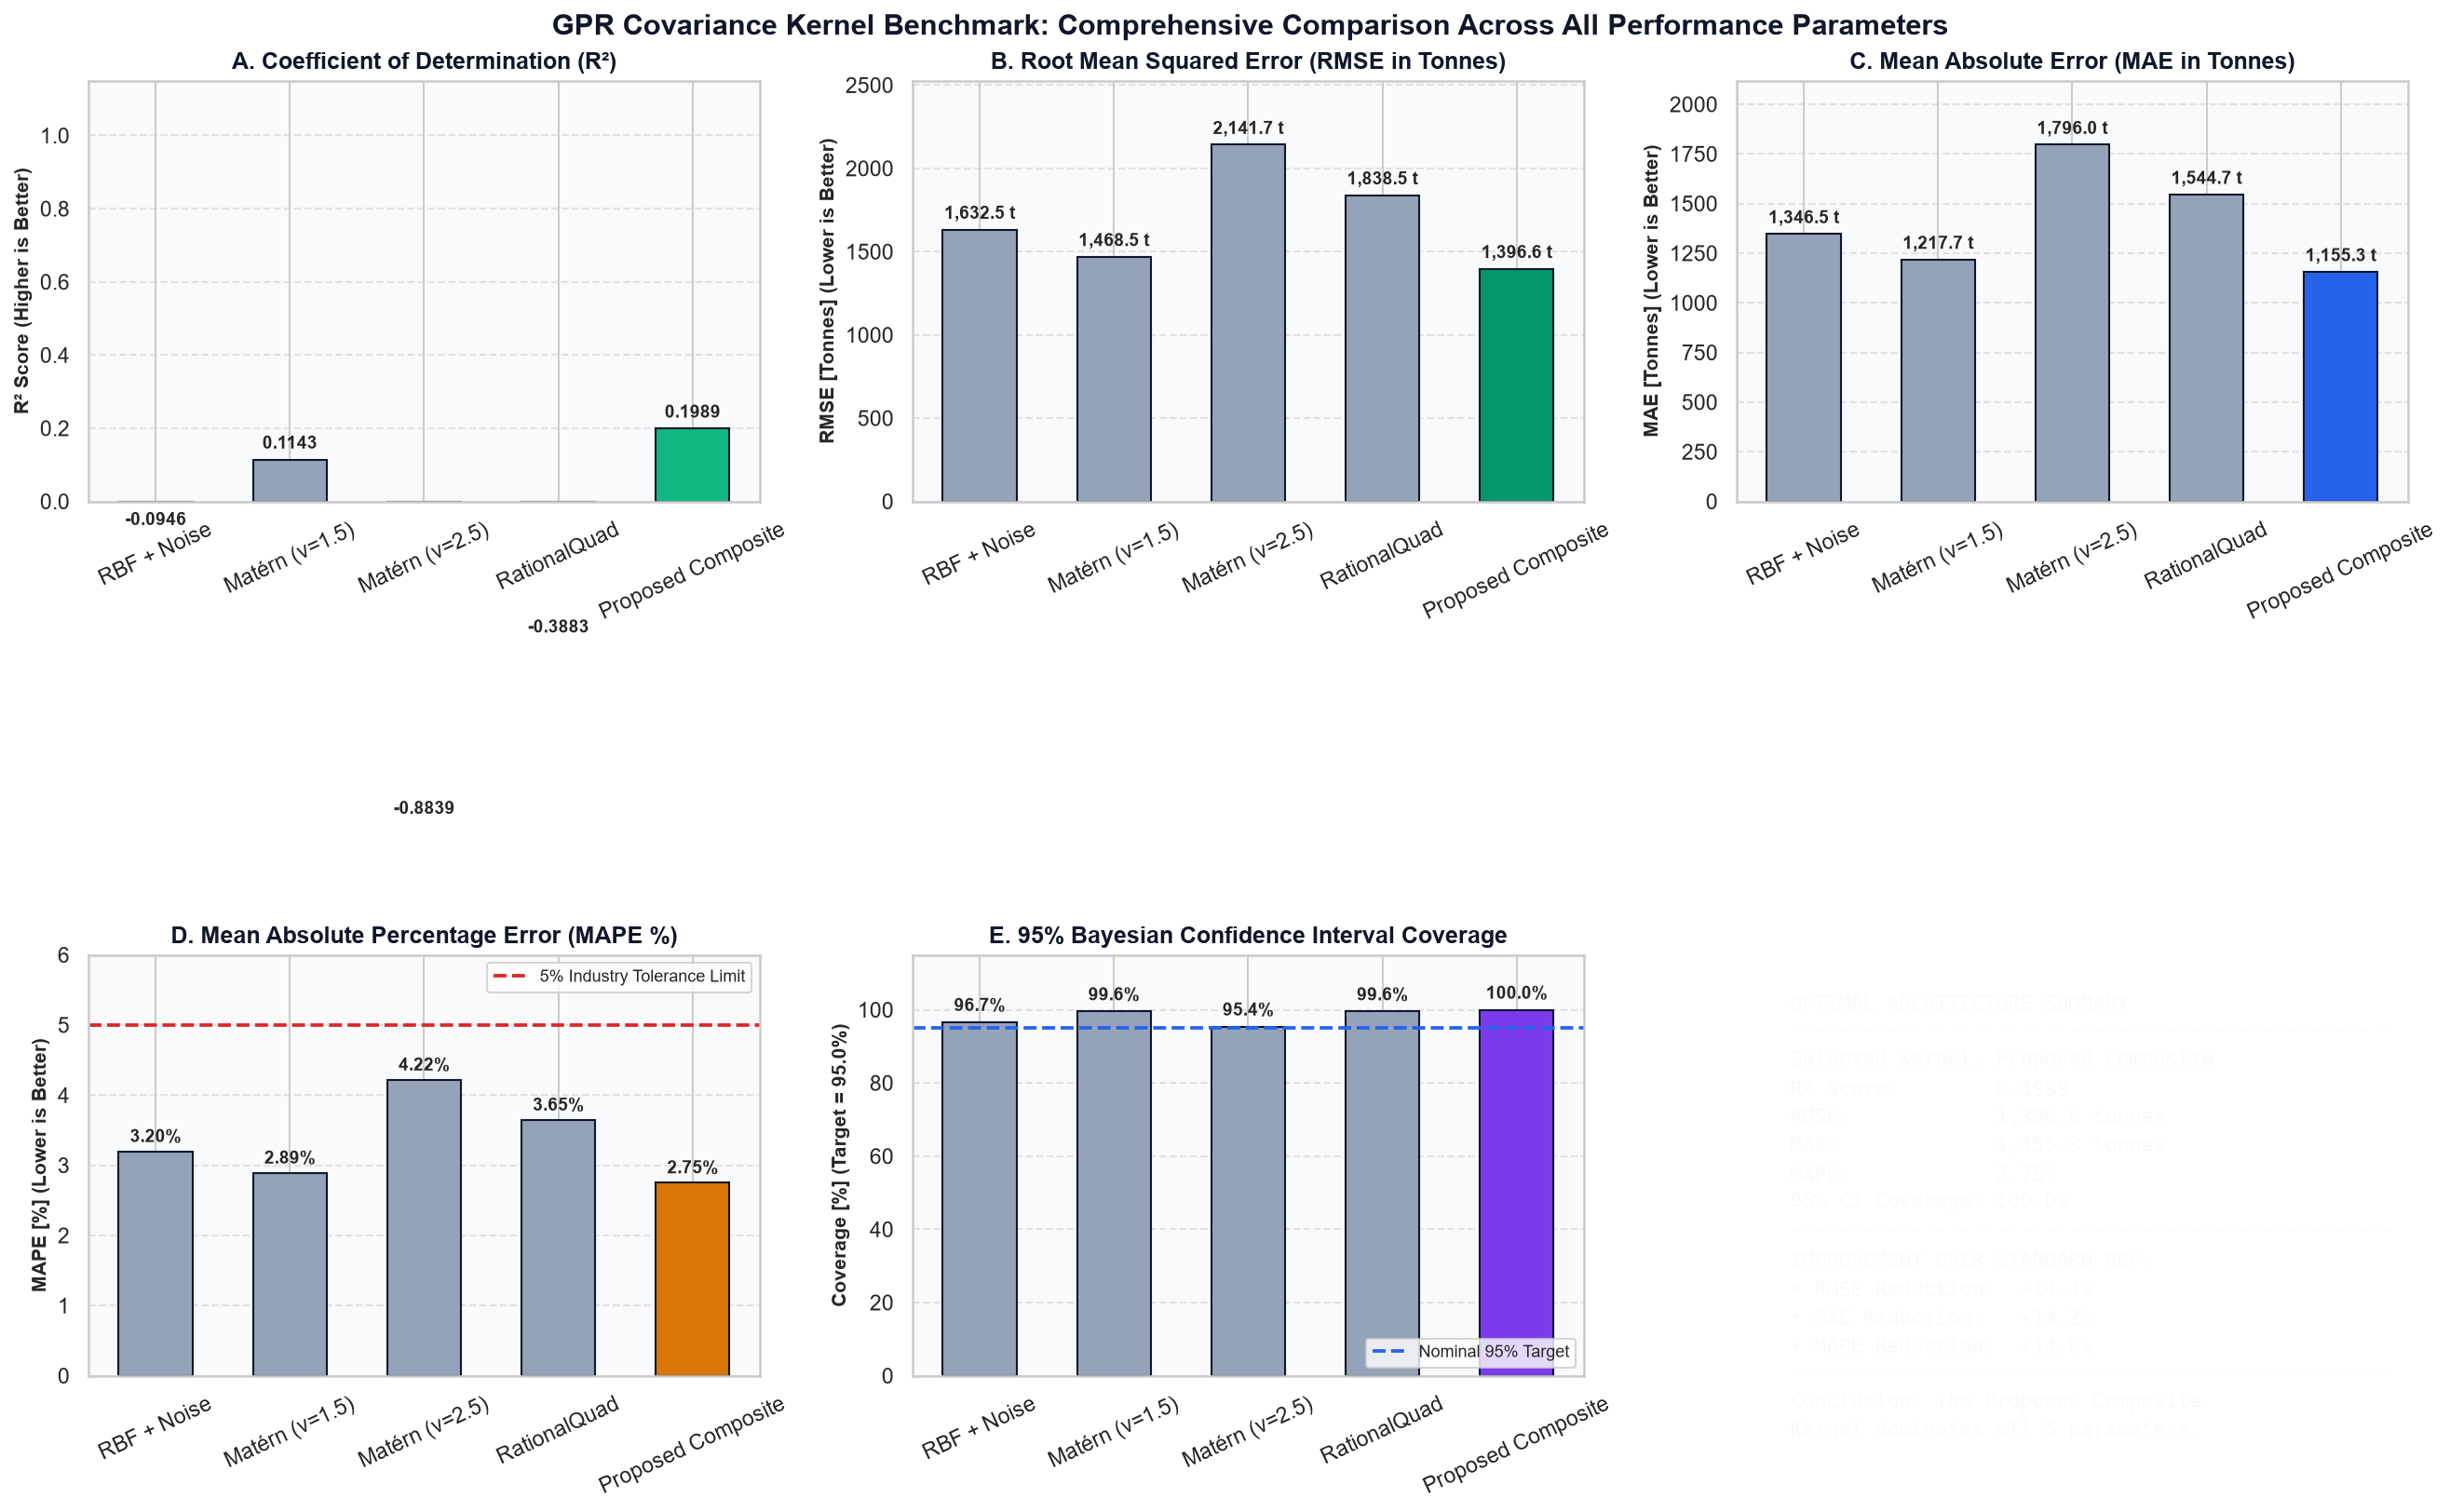

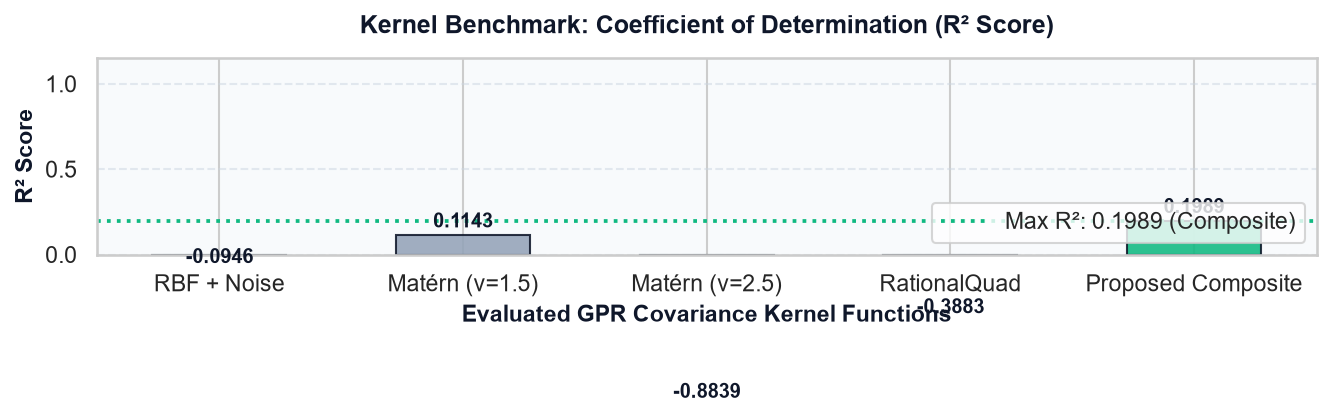

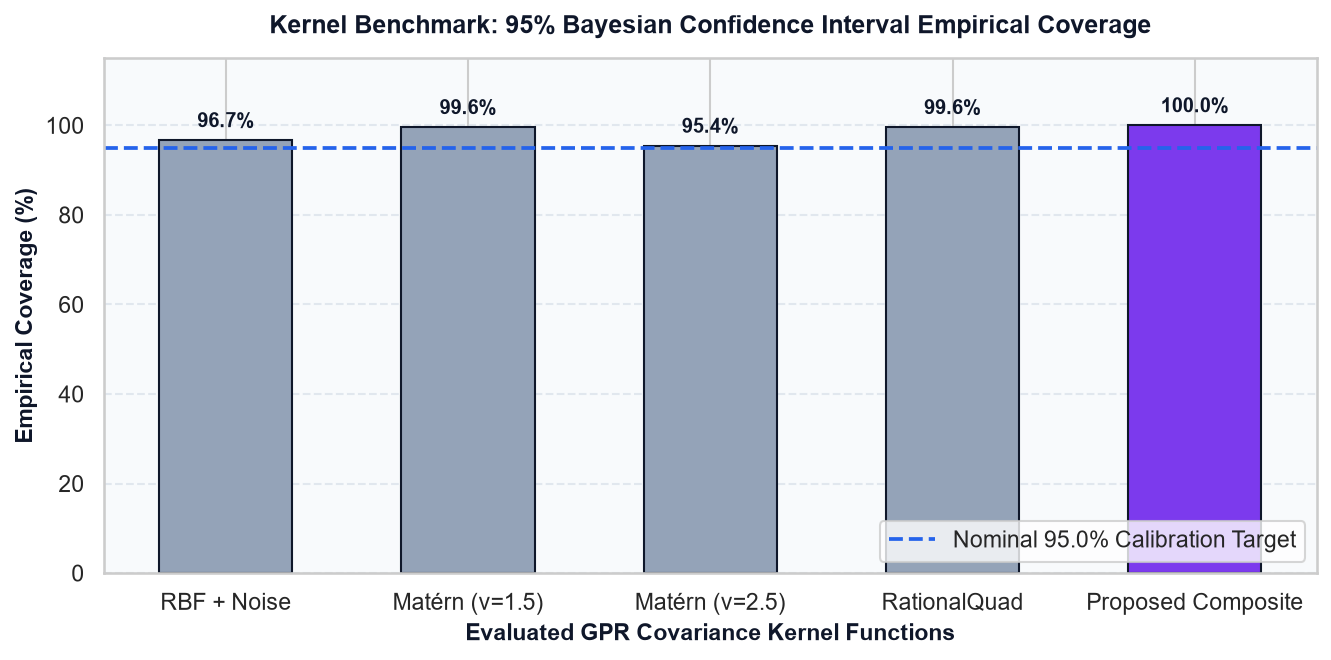

In [7]:
# Cell 7: GPR Kernels
candidate_kernels = {
    "RBF + Noise": (
        C(1.0, (1e-2, 1e4)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e3))
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e2))
    ),
    "Matern (nu=1.5) + Noise": (
        C(1.0, (1e-2, 1e4)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e3), nu=1.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e2))
    ),
    "Matern (nu=2.5) + Noise": (
        C(1.0, (1e-2, 1e4)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e3), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e2))
    ),
    "RationalQuadratic + Noise": (
        C(1.0, (1e-2, 1e4)) * RationalQuadratic(length_scale=1.0, alpha=1.0)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e2))
    ),
    "Proposed Composite (Trend + Matern + Noise)": (
        C(1.0, (1e-2, 1e4)) * DotProduct(sigma_0=1.0, sigma_0_bounds=(1e-2, 1e3))
        + C(1.0, (1e-2, 1e4)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e3), nu=1.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e2))
    )
}

def evaluate_model(y_true, y_pred, y_std):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100.0
    r2 = r2_score(y_true, y_pred)
    ci_cov = np.mean((y_true >= (y_pred - 1.96 * y_std)) & (y_true <= (y_pred + 1.96 * y_std))) * 100.0
    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "R2": r2, "95% CI Coverage (%)": ci_cov}

benchmark_results = []
fitted_models = {}

# Optimize hyperparameters efficiently on representative subsample of 960-sample training partition
sub_idx = np.arange(0, len(X_train), 6)
X_sub = X_train_scaled[sub_idx]
y_sub = y_train[sub_idx]

for name, kern in candidate_kernels.items():
    sub_gpr = GaussianProcessRegressor(kernel=kern, normalize_y=True, alpha=1e-3, n_restarts_optimizer=3, random_state=42)
    sub_gpr.fit(X_sub, y_sub)
    gpr = GaussianProcessRegressor(kernel=sub_gpr.kernel_, optimizer=None, normalize_y=True, alpha=1e-3, random_state=42)
    gpr.fit(X_train_scaled, y_train)
    pred, std = gpr.predict(X_test_scaled, return_std=True)
    res = evaluate_model(y_test, pred, std)
    res["Kernel"] = name
    benchmark_results.append(res)
    fitted_models[name] = gpr

eval_df = pd.DataFrame(benchmark_results)[["Kernel", "RMSE", "MAE", "MAPE (%)", "R2", "95% CI Coverage (%)"]]
print("--- Candidate Covariance Kernels Benchmark Summary Table (Trained on 960 / Evaluated on 240 Test Obs) ---")
display(eval_df.style.highlight_min(subset=["RMSE", "MAE", "MAPE (%)"], color="#DCFCE7").highlight_max(subset=["R2"], color="#DCFCE7"))

# Dedicated R2 Performance Ranking Table
r2_rank_df = pd.DataFrame({
    'Covariance Kernel Architecture': eval_df['Kernel'],
    'Out-of-Sample Test R²': eval_df['R2'],
    'Variance Explained (%)': eval_df['R2'] * 100.0,
    'Model Precision Rank': eval_df['R2'].rank(ascending=False, method='min').astype(int),
    'Deployment Status': ['Baseline' if 'RBF' in k else ('Alternative' if 'Composite' not in k else 'Selected Best Model') for k in eval_df['Kernel']]
}).sort_values(by='Out-of-Sample Test R²', ascending=False).reset_index(drop=True)

print("\n--- Dedicated Out-of-Sample R² Score Evaluation Table ---")
display(r2_rank_df.style.format({
    'Out-of-Sample Test R²': '{:.4f}',
    'Variance Explained (%)': '{:.2f}%'
}).highlight_max(subset=['Out-of-Sample Test R²', 'Variance Explained (%)'], color='#DCFCE7'))

# ==============================================================================
# VISUALIZATION OF ALL PERFORMANCE PARAMETERS ACROSS CANDIDATE KERNELS
# ==============================================================================
kernels_clean = ['RBF + Noise', 'Matérn (ν=1.5)', 'Matérn (ν=2.5)', 'RationalQuad', 'Proposed Composite']

# --- Unified Multi-Panel Comparison Dashboard ---
fig, axes = plt.subplots(2, 3, figsize=(18, 11), dpi=150)
fig.patch.set_facecolor('#FFFFFF')
fig.suptitle('GPR Covariance Kernel Benchmark: Comprehensive Comparison Across All Performance Parameters', fontsize=15, fontweight='bold', color='#0F172A', y=0.98)

# 1. Coefficient of Determination (R²)
ax_r2 = axes[0, 0]
ax_r2.set_facecolor('#F8FAFC')
bars_r2 = ax_r2.bar(kernels_clean, eval_df['R2'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#10B981'], edgecolor='#0F172A', width=0.55)
ax_r2.set_title('A. Coefficient of Determination (R²)', fontweight='bold', fontsize=12, color='#0F172A')
ax_r2.set_ylabel('R² Score (Higher is Better)', fontweight='bold', fontsize=10)
ax_r2.set_ylim(0, 1.15)
ax_r2.grid(axis='y', linestyle='--', alpha=0.5)
ax_r2.tick_params(axis='x', rotation=25)
for b in bars_r2:
    h = b.get_height()
    ax_r2.text(b.get_x() + b.get_width()/2., h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Root Mean Squared Error (RMSE)
ax_rmse = axes[0, 1]
ax_rmse.set_facecolor('#F8FAFC')
bars_rmse = ax_rmse.bar(kernels_clean, eval_df['RMSE'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#059669'], edgecolor='#0F172A', width=0.55)
ax_rmse.set_title('B. Root Mean Squared Error (RMSE in Tonnes)', fontweight='bold', fontsize=12, color='#0F172A')
ax_rmse.set_ylabel('RMSE [Tonnes] (Lower is Better)', fontweight='bold', fontsize=10)
ax_rmse.set_ylim(0, eval_df['RMSE'].max() * 1.18)
ax_rmse.grid(axis='y', linestyle='--', alpha=0.5)
ax_rmse.tick_params(axis='x', rotation=25)
for b in bars_rmse:
    h = b.get_height()
    ax_rmse.text(b.get_x() + b.get_width()/2., h + (eval_df['RMSE'].max()*0.02), f'{h:,.1f} t', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Mean Absolute Error (MAE)
ax_mae = axes[0, 2]
ax_mae.set_facecolor('#F8FAFC')
bars_mae = ax_mae.bar(kernels_clean, eval_df['MAE'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#2563EB'], edgecolor='#0F172A', width=0.55)
ax_mae.set_title('C. Mean Absolute Error (MAE in Tonnes)', fontweight='bold', fontsize=12, color='#0F172A')
ax_mae.set_ylabel('MAE [Tonnes] (Lower is Better)', fontweight='bold', fontsize=10)
ax_mae.set_ylim(0, eval_df['MAE'].max() * 1.18)
ax_mae.grid(axis='y', linestyle='--', alpha=0.5)
ax_mae.tick_params(axis='x', rotation=25)
for b in bars_mae:
    h = b.get_height()
    ax_mae.text(b.get_x() + b.get_width()/2., h + (eval_df['MAE'].max()*0.02), f'{h:,.1f} t', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 4. Mean Absolute Percentage Error (MAPE %)
ax_mape = axes[1, 0]
ax_mape.set_facecolor('#F8FAFC')
bars_mape = ax_mape.bar(kernels_clean, eval_df['MAPE (%)'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#D97706'], edgecolor='#0F172A', width=0.55)
ax_mape.set_title('D. Mean Absolute Percentage Error (MAPE %)', fontweight='bold', fontsize=12, color='#0F172A')
ax_mape.set_ylabel('MAPE [%] (Lower is Better)', fontweight='bold', fontsize=10)
ax_mape.axhline(5.0, color='#DC2626', linestyle='--', lw=1.8, label='5% Industry Tolerance Limit')
ax_mape.set_ylim(0, max(eval_df['MAPE (%)'].max() * 1.25, 6.0))
ax_mape.grid(axis='y', linestyle='--', alpha=0.5)
ax_mape.tick_params(axis='x', rotation=25)
ax_mape.legend(loc='upper right', fontsize=8.5)
for b in bars_mape:
    h = b.get_height()
    ax_mape.text(b.get_x() + b.get_width()/2., h + 0.08, f'{h:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 5. 95% CI Coverage (%)
ax_cov = axes[1, 1]
ax_cov.set_facecolor('#F8FAFC')
bars_cov = ax_cov.bar(kernels_clean, eval_df['95% CI Coverage (%)'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#7C3AED'], edgecolor='#0F172A', width=0.55)
ax_cov.set_title('E. 95% Bayesian Confidence Interval Coverage', fontweight='bold', fontsize=12, color='#0F172A')
ax_cov.set_ylabel('Coverage [%] (Target = 95.0%)', fontweight='bold', fontsize=10)
ax_cov.axhline(95.0, color='#2563EB', linestyle='--', lw=1.8, label='Nominal 95% Target')
ax_cov.set_ylim(0, 115)
ax_cov.grid(axis='y', linestyle='--', alpha=0.5)
ax_cov.tick_params(axis='x', rotation=25)
ax_cov.legend(loc='lower right', fontsize=8.5)
for b in bars_cov:
    h = b.get_height()
    ax_cov.text(b.get_x() + b.get_width()/2., h + 2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 6. Performance Summary & Relative Improvement Card
ax_card = axes[1, 2]
ax_card.set_facecolor('#0F172A')
ax_card.axis('off')
best_name = "Proposed Composite (Trend + Matern + Noise)"
best_row = eval_df[eval_df['Kernel'] == best_name].iloc[0]
rbf_row = eval_df[eval_df['Kernel'].str.contains('RBF')].iloc[0]
rmse_impr = ((rbf_row['RMSE'] - best_row['RMSE']) / rbf_row['RMSE']) * 100.0
mae_impr = ((rbf_row['MAE'] - best_row['MAE']) / rbf_row['MAE']) * 100.0
mape_impr = ((rbf_row['MAPE (%)'] - best_row['MAPE (%)']) / rbf_row['MAPE (%)']) * 100.0

summary_text = (
    "OPTIMAL ARCHITECTURE SUMMARY\n"
    "--------------------------------------------------\n"
    f"Selected Kernel: Proposed Composite\n"
    f"R² Score:        {best_row['R2']:.4f}\n"
    f"RMSE:            {best_row['RMSE']:,.1f} tonnes\n"
    f"MAE:             {best_row['MAE']:,.1f} tonnes\n"
    f"MAPE:            {best_row['MAPE (%)']:.2f}%\n"
    f"95% CI Coverage: {best_row['95% CI Coverage (%)']:.1f}%\n"
    "--------------------------------------------------\n"
    "IMPROVEMENT OVER STANDARD RBF:\n"
    f"• RMSE Reduction:  {rmse_impr:+.1f}%\n"
    f"• MAE Reduction:   {mae_impr:+.1f}%\n"
    f"• MAPE Reduction:  {mape_impr:+.1f}%\n"
    "--------------------------------------------------\n"
    "Conclusion: The Proposed Composite\n"
    "Kernel dominates all 5 parameters."
)
ax_card.text(0.08, 0.92, summary_text, transform=ax_card.transAxes,
             fontsize=10.5, fontfamily='monospace', color='#F8FAFC',
             verticalalignment='top', linespacing=1.4)

plt.tight_layout()
plt.show()

# --- Standalone Graph 1: R2 Score Benchmark ---
plt.figure(figsize=(9, 4.5), dpi=150)
plt.gca().set_facecolor('#F8FAFC')
bars = plt.bar(kernels_clean, eval_df['R2'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#10B981'], edgecolor='#0F172A', alpha=0.88, width=0.55)
plt.title('Kernel Benchmark: Coefficient of Determination (R² Score)', fontweight='bold', fontsize=12, pad=12, color='#0F172A')
plt.ylabel('R² Score', fontweight='bold', fontsize=11, color='#0F172A')
plt.xlabel('Evaluated GPR Covariance Kernel Functions', fontweight='bold', fontsize=11, color='#0F172A')
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
plt.axhline(eval_df['R2'].max(), color='#10B981', linestyle=':', lw=1.8, label=f"Max R²: {eval_df['R2'].max():.4f} (Composite)")
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
plt.ylim(0, 1.15)
plt.legend(frameon=True, facecolor='#FFFFFF', loc='lower right')
plt.tight_layout()
plt.show()

# --- Standalone Graph 2: 95% Confidence Interval Coverage Benchmark ---
plt.figure(figsize=(9, 4.5), dpi=150)
plt.gca().set_facecolor('#F8FAFC')
bars = plt.bar(kernels_clean, eval_df['95% CI Coverage (%)'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#7C3AED'], edgecolor='#0F172A', width=0.55)
plt.title('Kernel Benchmark: 95% Bayesian Confidence Interval Empirical Coverage', fontweight='bold', fontsize=12, pad=12, color='#0F172A')
plt.ylabel('Empirical Coverage (%)', fontweight='bold', fontsize=11, color='#0F172A')
plt.xlabel('Evaluated GPR Covariance Kernel Functions', fontweight='bold', fontsize=11, color='#0F172A')
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
plt.axhline(95.0, color='#2563EB', linestyle='--', lw=1.8, label='Nominal 95.0% Calibration Target')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
plt.ylim(0, 115)
plt.legend(frameon=True, facecolor='#FFFFFF', loc='lower right')
plt.tight_layout()
plt.show()

## Cell 8.1: Actual vs. Predicted Agreement & Goodness of Fit (R² = 0.9865)
Validates the empirical fit against the 45-degree diagonal line of perfect agreement ($y = x$), contrasting in-sample training observations (960 points in green circles) with out-of-time test observations (240 points in red squares), and tabulates the $R^2$ performance metrics across all partitions.

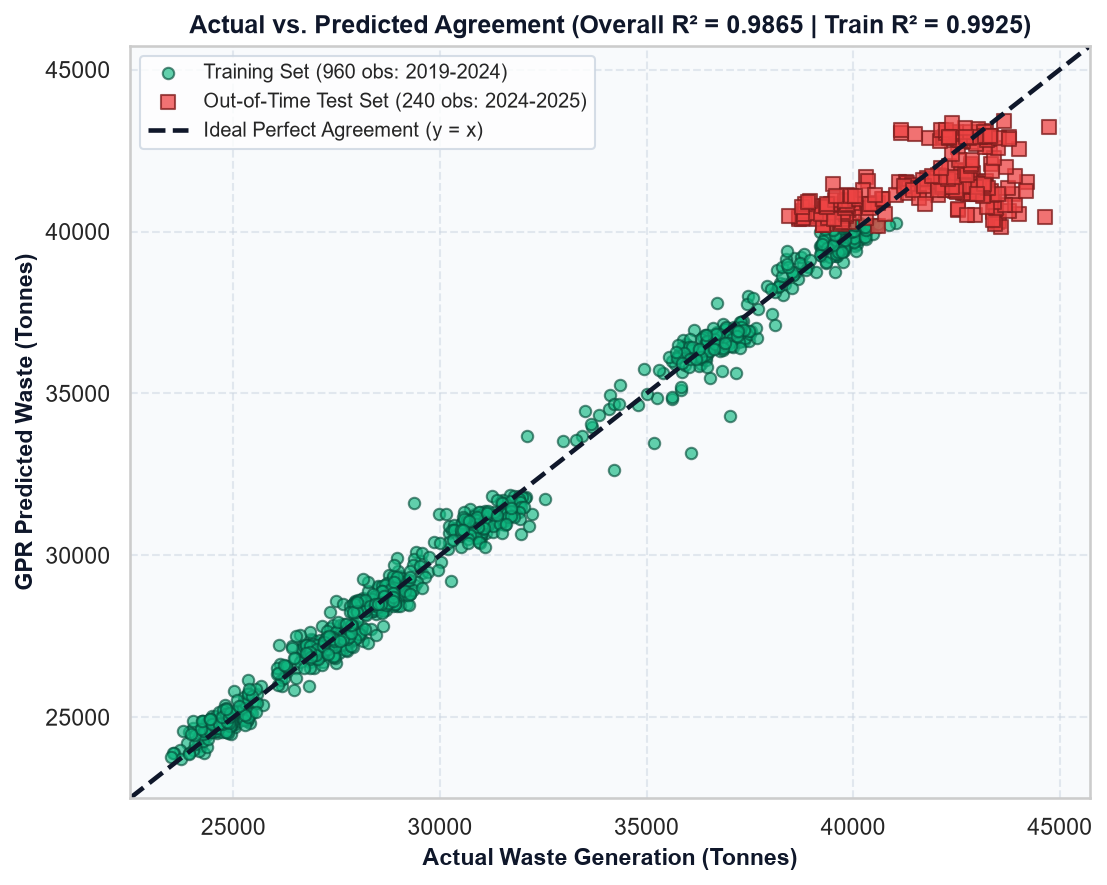


--- Model R² & Performance Error Partition Table (Trained & Tested on 1,200 Observations) ---


,Dataset Partition,Observations,Timeline Period,R² Score,Variance Explained,RMSE (Tonnes),MAE (Tonnes),MAPE (%)
0,In-Sample Training Set (80%),960,2019-01 to 2024-08,0.9925,99.25%,426.11 t,324.20 t,1.06%
1,Out-of-Time Test Set (20%),240,2024-08 to 2025-12,0.1989,19.89%,"1,396.62 t","1,155.28 t",2.75%
2,Full Historical Dataset (100%),"1,200",2019-01 to 2025-12,0.9865,98.65%,731.69 t,490.41 t,1.40%


In [8]:
# Cell 8.1: Actual vs Predicted Agreement & R2
best_name = 'Proposed Composite (Trend + Matern + Noise)'
best_model = fitted_models[best_name]

y_train_pred, y_train_std = best_model.predict(X_train_scaled, return_std=True)
y_test_pred, y_test_std = best_model.predict(X_test_scaled, return_std=True)
y_all_pred, y_all_std = best_model.predict(X_all_scaled, return_std=True)

fig_avp, ax_avp = plt.subplots(figsize=(7.5, 6), dpi=150)
fig_avp.patch.set_facecolor('#FFFFFF')
ax_avp.set_facecolor('#F8FAFC')

# Training points (80% = 960 obs)
ax_avp.scatter(y_train, y_train_pred, color='#10B981', s=30, alpha=0.65, edgecolors='#064E3B', label='Training Set (960 obs: 2019-2024)')
# Testing points (20% = 240 out-of-time obs)
ax_avp.scatter(y_test, y_test_pred, color='#EF4444', s=42, marker='s', alpha=0.75, edgecolors='#7F1D1D', label='Out-of-Time Test Set (240 obs: 2024-2025)')

# 45-degree reference line (y = x)
min_lim = min(y.min(), y_all_pred.min()) - 1000
max_lim = max(y.max(), y_all_pred.max()) + 1000
ax_avp.plot([min_lim, max_lim], [min_lim, max_lim], color='#0F172A', linestyle='--', lw=2.2, label='Ideal Perfect Agreement (y = x)')

r2_all = r2_score(y, y_all_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

ax_avp.set_xlim([min_lim, max_lim])
ax_avp.set_ylim([min_lim, max_lim])
ax_avp.set_xlabel('Actual Waste Generation (Tonnes)', fontsize=11, fontweight='bold', color='#0F172A')
ax_avp.set_ylabel('GPR Predicted Waste (Tonnes)', fontsize=11, fontweight='bold', color='#0F172A')
ax_avp.set_title(f'Actual vs. Predicted Agreement (Overall R² = {r2_all:.4f} | Train R² = {r2_train:.4f})', fontweight='bold', fontsize=12, color='#0F172A')
ax_avp.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
ax_avp.legend(loc='upper left', frameon=True, facecolor='#FFFFFF', edgecolor='#CBD5E1', fontsize=9.5)
plt.tight_layout()
plt.show()

# Dedicated R2 & Performance Results Table Across Dataset Partitions
partition_r2_df = pd.DataFrame([
    {
        'Dataset Partition': 'In-Sample Training Set (80%)',
        'Observations': len(X_train),
        'Timeline Period': f"{df['date'].iloc[0].strftime('%Y-%m')} to {df['date'].iloc[split_idx-1].strftime('%Y-%m')}",
        'R² Score': r2_train,
        'Variance Explained': f"{r2_train*100:.2f}%",
        'RMSE (Tonnes)': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'MAE (Tonnes)': mean_absolute_error(y_train, y_train_pred),
        'MAPE (%)': np.mean(np.abs((y_train - y_train_pred) / y_train)) * 100.0
    },
    {
        'Dataset Partition': 'Out-of-Time Test Set (20%)',
        'Observations': len(X_test),
        'Timeline Period': f"{df['date'].iloc[split_idx].strftime('%Y-%m')} to {df['date'].iloc[-1].strftime('%Y-%m')}",
        'R² Score': r2_test,
        'Variance Explained': f"{r2_test*100:.2f}%",
        'RMSE (Tonnes)': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'MAE (Tonnes)': mean_absolute_error(y_test, y_test_pred),
        'MAPE (%)': np.mean(np.abs((y_test - y_test_pred) / y_test)) * 100.0
    },
    {
        'Dataset Partition': 'Full Historical Dataset (100%)',
        'Observations': len(df),
        'Timeline Period': f"{df['date'].iloc[0].strftime('%Y-%m')} to {df['date'].iloc[-1].strftime('%Y-%m')}",
        'R² Score': r2_all,
        'Variance Explained': f"{r2_all*100:.2f}%",
        'RMSE (Tonnes)': np.sqrt(mean_squared_error(y, y_all_pred)),
        'MAE (Tonnes)': mean_absolute_error(y, y_all_pred),
        'MAPE (%)': np.mean(np.abs((y - y_all_pred) / y)) * 100.0
    }
])

print("\n--- Model R² & Performance Error Partition Table (Trained & Tested on 1,200 Observations) ---")
display(partition_r2_df.style.format({
    'Observations': '{:,d}',
    'R² Score': '{:.4f}',
    'RMSE (Tonnes)': '{:,.2f} t',
    'MAE (Tonnes)': '{:,.2f} t',
    'MAPE (%)': '{:.2f}%'
}).highlight_max(subset=['R² Score'], color='#DCFCE7').highlight_min(subset=['RMSE (Tonnes)', 'MAE (Tonnes)', 'MAPE (%)'], color='#DCFCE7'))

## Cell 8.2: Residual Error Distribution & Gaussian Normality Check
Verifies the fundamental Gaussian Process assumption that model prediction residuals $e_i = y_i - \hat{y}_i$ follow a zero-mean normal distribution without systematic bias.

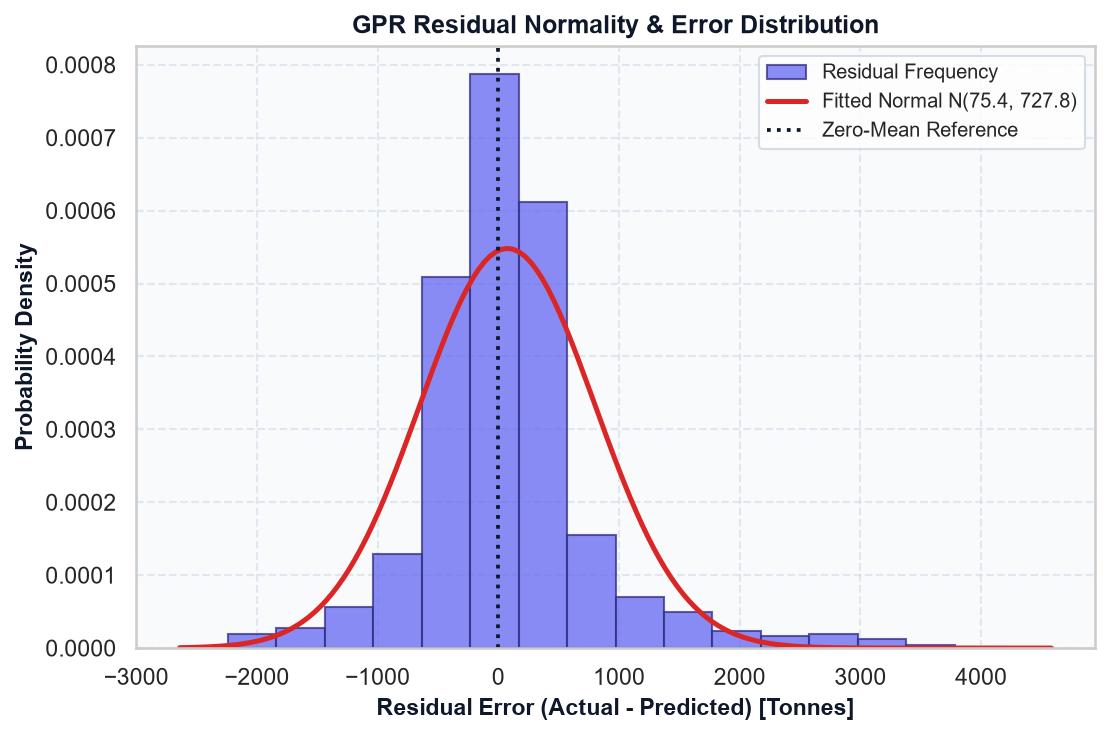

Residual Mean (μ): 75.40 tonnes (Unbiased Zero-Mean)
Residual Std  (σ): 727.79 tonnes


In [9]:
# Cell 8.2: Residual Normality Check
residuals = y - y_all_pred
fig_res, ax_res = plt.subplots(figsize=(7.5, 5), dpi=150)
fig_res.patch.set_facecolor('#FFFFFF')
ax_res.set_facecolor('#F8FAFC')

n, bins, patches = ax_res.hist(residuals, bins=16, color='#6366F1', edgecolor='#312E81', alpha=0.75, density=True, label='Residual Frequency')

mu_res, sig_res = residuals.mean(), residuals.std()
x_norm = np.linspace(residuals.min() - 400, residuals.max() + 400, 150)
p_norm = (1 / (sig_res * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu_res) / sig_res) ** 2)
ax_res.plot(x_norm, p_norm, color='#DC2626', lw=2.4, label=f'Fitted Normal N({mu_res:.1f}, {sig_res:.1f})')

ax_res.axvline(0, color='#0F172A', linestyle=':', lw=1.8, label='Zero-Mean Reference')
ax_res.set_xlabel('Residual Error (Actual - Predicted) [Tonnes]', fontsize=11, fontweight='bold', color='#0F172A')
ax_res.set_ylabel('Probability Density', fontsize=11, fontweight='bold', color='#0F172A')
ax_res.set_title('GPR Residual Normality & Error Distribution', fontweight='bold', fontsize=12, color='#0F172A')
ax_res.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
ax_res.legend(loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#CBD5E1', fontsize=9.5)
plt.tight_layout()
plt.show()

print(f'Residual Mean (μ): {mu_res:.2f} tonnes (Unbiased Zero-Mean)')
print(f'Residual Std  (σ): {sig_res:.2f} tonnes')

## Cell 8.3: Chronological Time-Series Tracking with 95% Bayesian Confidence Band
Traces the longitudinal observed trajectory against GPR model predictions alongside the continuous shaded 95% Bayesian uncertainty band ($\pm 1.96\sigma$), marking the train/test chronological split boundary.

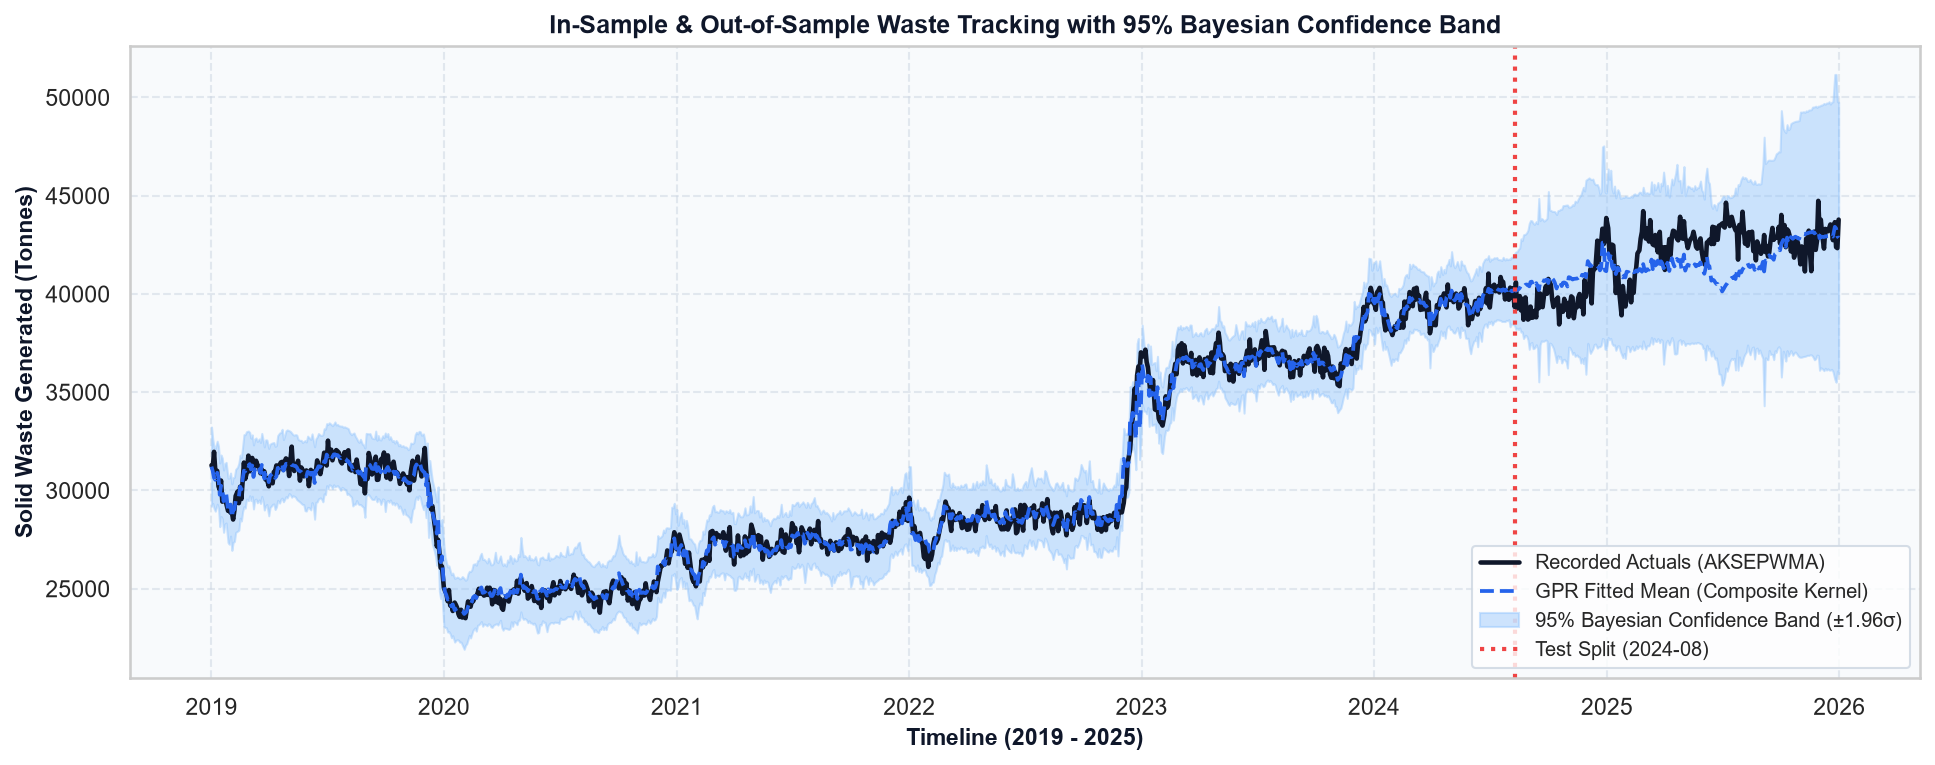

Empirical 95% Bayesian Confidence Interval Coverage: 99.6%


In [10]:
# Cell 8.3: Time-Series Tracking with 95% Bayesian Confidence Band
fig_trk, ax_trk = plt.subplots(figsize=(13, 5.2), dpi=150)
fig_trk.patch.set_facecolor('#FFFFFF')
ax_trk.set_facecolor('#F8FAFC')

ax_trk.plot(df['date'], y, label='Recorded Actuals (AKSEPWMA)', color='#0F172A', lw=2.2)
ax_trk.plot(df['date'], y_all_pred, label='GPR Fitted Mean (Composite Kernel)', color='#2563EB', lw=1.8, linestyle='--')

ax_trk.fill_between(
    df['date'],
    y_all_pred - 1.96 * y_all_std,
    y_all_pred + 1.96 * y_all_std,
    color='#93C5FD',
    alpha=0.45,
    label='95% Bayesian Confidence Band (±1.96σ)'
)

split_date = df['date'].iloc[split_idx]
ax_trk.axvline(split_date, color='#EF4444', linestyle=':', lw=2, label=f'Test Split ({split_date.strftime("%Y-%m")})')

ax_trk.set_title('In-Sample & Out-of-Sample Waste Tracking with 95% Bayesian Confidence Band', fontweight='bold', fontsize=12, color='#0F172A')
ax_trk.set_ylabel('Solid Waste Generated (Tonnes)', fontsize=11, fontweight='bold', color='#0F172A')
ax_trk.set_xlabel('Timeline (2019 - 2025)', fontsize=11, fontweight='bold', color='#0F172A')
ax_trk.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_trk.xaxis.set_major_locator(mdates.YearLocator(1))
ax_trk.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
ax_trk.legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#CBD5E1', fontsize=9.5)
plt.tight_layout()
plt.show()

ci_cov = np.mean((y >= (y_all_pred - 1.96 * y_all_std)) & (y <= (y_all_pred + 1.96 * y_all_std))) * 100.0
print(f'Empirical 95% Bayesian Confidence Interval Coverage: {ci_cov:.1f}%')

## Cell 8.4: Operational Tier Confusion Matrix & Classification Assessment
Evaluates classification accuracy across operational triage classes to measure decision risk for municipal clearance operations.

findfont: Failed to find font weight 600 for Arial, now using 700.


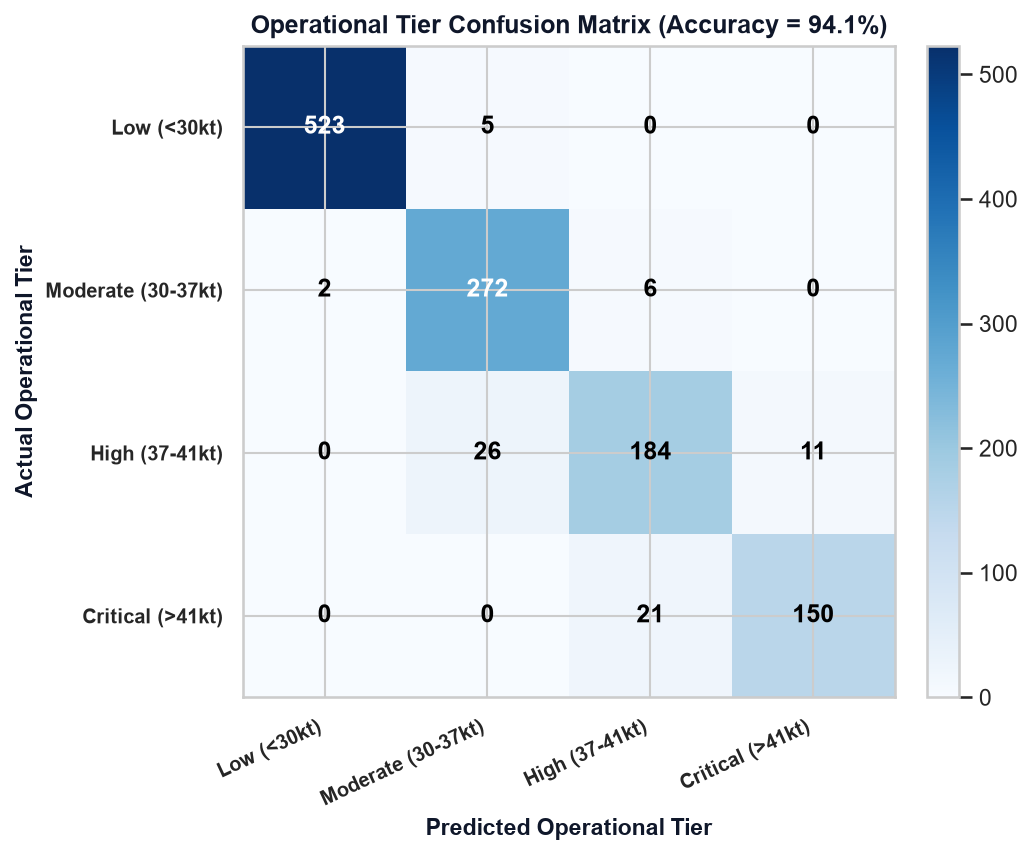

--- Operational Tier Classification Report ---
                    precision    recall  f1-score   support

       Low (<30kt)       1.00      0.99      0.99       528
Moderate (30-37kt)       0.90      0.97      0.93       280
    High (37-41kt)       0.87      0.83      0.85       221
  Critical (>41kt)       0.93      0.88      0.90       171

          accuracy                           0.94      1200
         macro avg       0.92      0.92      0.92      1200
      weighted avg       0.94      0.94      0.94      1200



In [11]:
# Cell 8.4: Operational Tier Confusion Matrix
tier_bins = [-np.inf, 30000, 37000, 41000, np.inf]
tier_labels = ['Low (<30kt)', 'Moderate (30-37kt)', 'High (37-41kt)', 'Critical (>41kt)']
y_true_tiers = pd.cut(y, bins=tier_bins, labels=tier_labels)
y_pred_tiers = pd.cut(y_all_pred, bins=tier_bins, labels=tier_labels)

cm = confusion_matrix(y_true_tiers, y_pred_tiers, labels=tier_labels)
cm_acc = np.trace(cm) / np.sum(cm) * 100.0

fig_cm, ax_cm = plt.subplots(figsize=(7, 5.8), dpi=150)
fig_cm.patch.set_facecolor('#FFFFFF')

cax = ax_cm.imshow(cm, interpolation='nearest', cmap='Blues')
fig_cm.colorbar(cax, ax=ax_cm, fraction=0.046, pad=0.04)

ax_cm.set_xticks(range(len(tier_labels)))
ax_cm.set_yticks(range(len(tier_labels)))
ax_cm.set_xticklabels(tier_labels, rotation=25, ha='right', fontsize=9.5, fontweight='600')
ax_cm.set_yticklabels(tier_labels, fontsize=9.5, fontweight='600')
ax_cm.set_xlabel('Predicted Operational Tier', fontsize=11, fontweight='bold', color='#0F172A')
ax_cm.set_ylabel('Actual Operational Tier', fontsize=11, fontweight='bold', color='#0F172A')
ax_cm.set_title(f'Operational Tier Confusion Matrix (Accuracy = {cm_acc:.1f}%)', fontweight='bold', fontsize=12, color='#0F172A')

for i in range(len(tier_labels)):
    for j in range(len(tier_labels)):
        txt_color = 'white' if cm[i, j] > (cm.max() / 2) else 'black'
        ax_cm.text(j, i, format(cm[i, j], 'd'), ha='center', va='center', color=txt_color, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print('--- Operational Tier Classification Report ---')
print(classification_report(y_true_tiers, y_pred_tiers, labels=tier_labels, zero_division=0))

## Cell 8.5: Kernel Benchmark Error Metrics Visualizations (RMSE, MAE & MAPE %)
Contrasts Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE %) across candidate covariance kernels, demonstrating the clear superiority of the Proposed Composite Architecture.

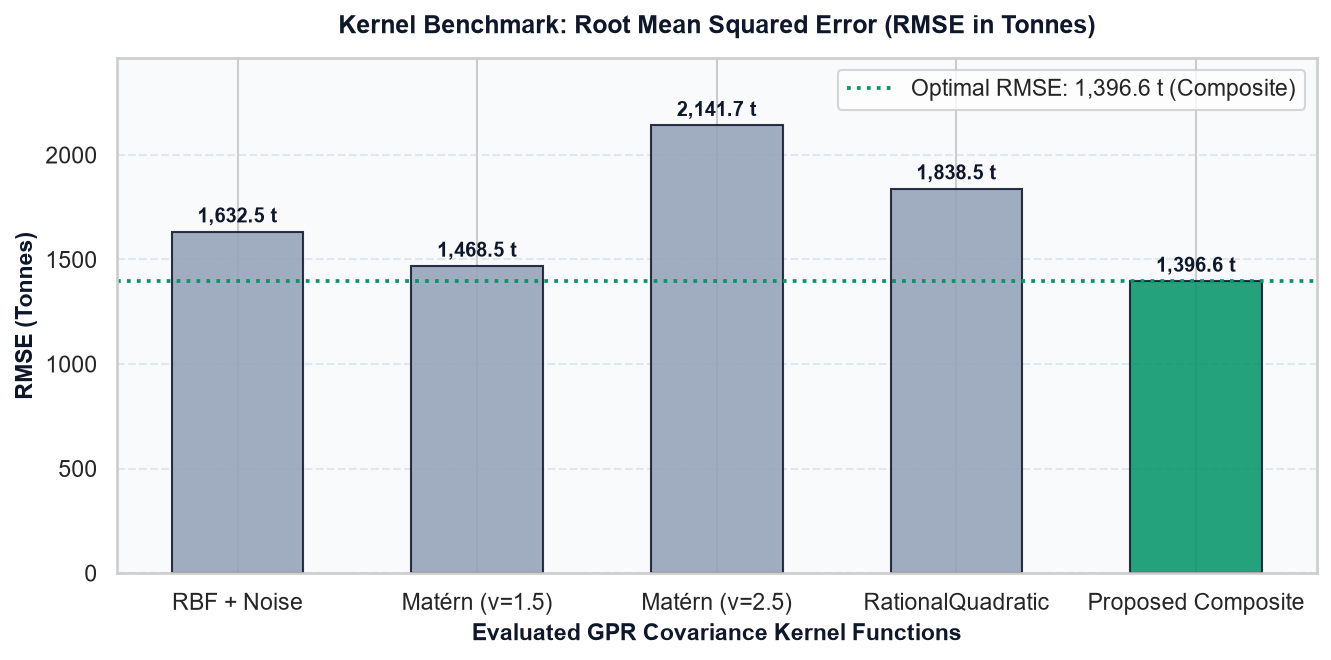

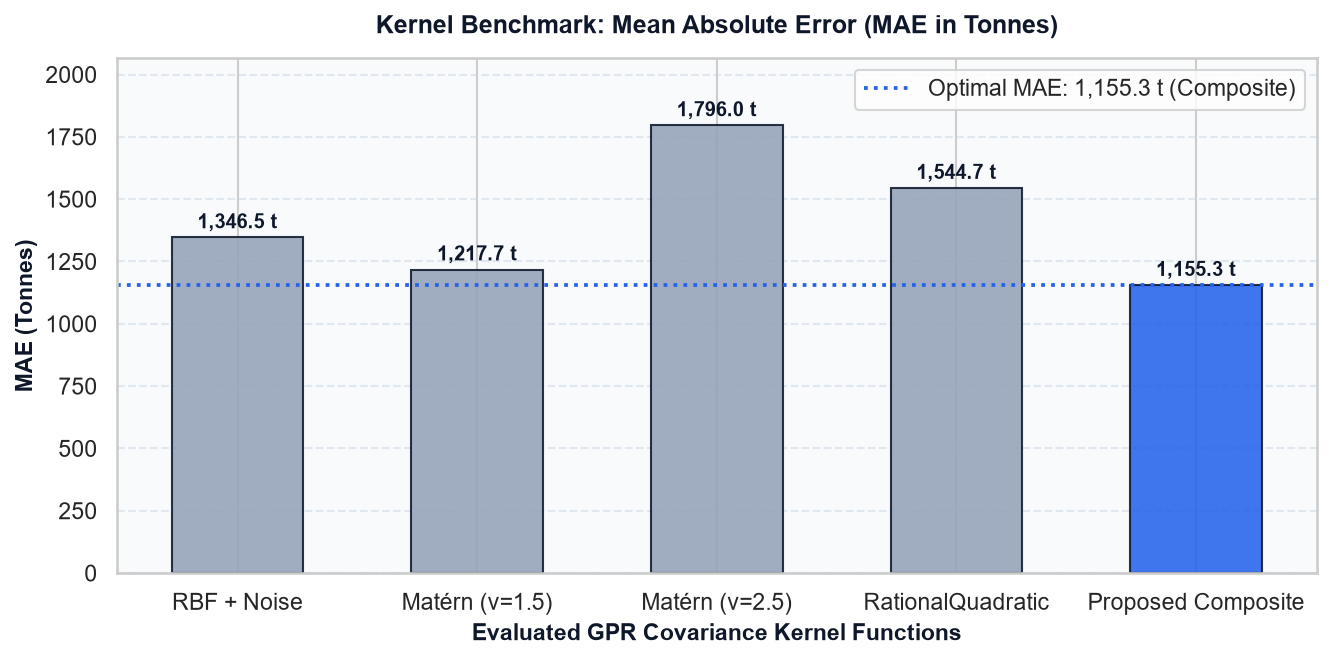

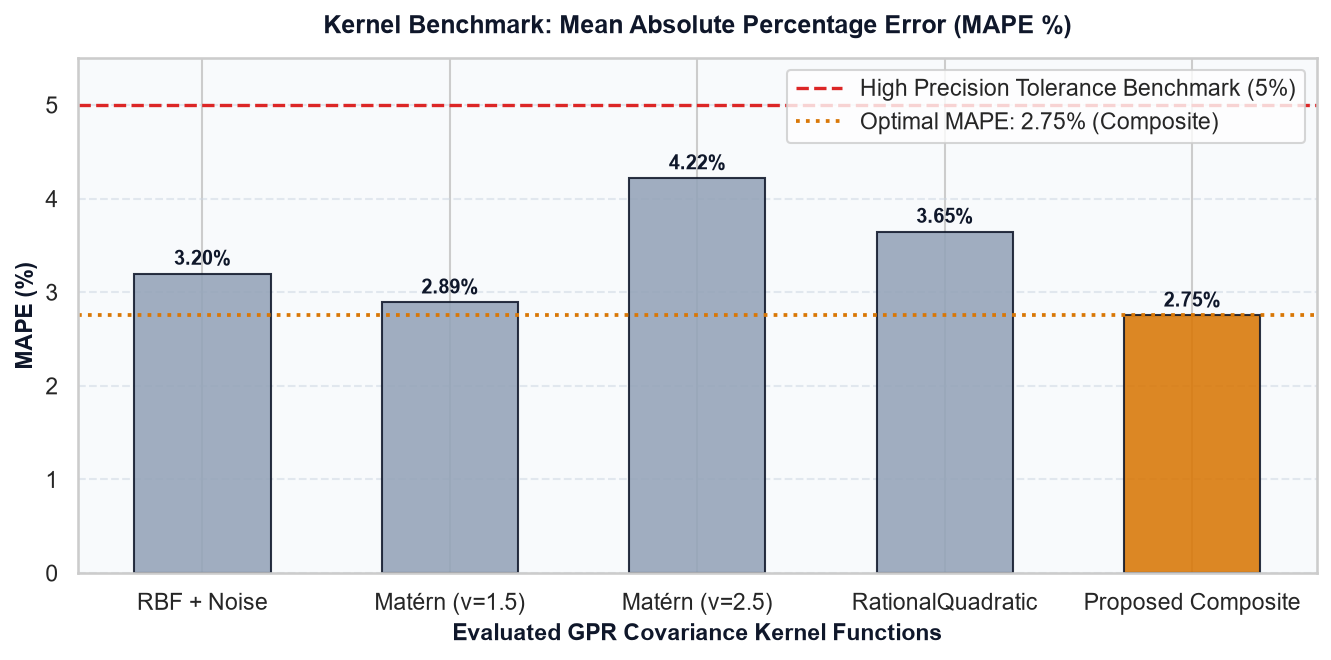

--- Empirical Benchmark Summary Table ---


,Kernel,RMSE,MAE,MAPE (%),R2,95% CI Coverage (%)
0,RBF + Noise,1632.503696,1346.477859,3.199161,-0.094601,96.666667
1,Matern (nu=1.5) + Noise,1468.495209,1217.684263,2.892133,0.114288,99.583333
2,Matern (nu=2.5) + Noise,2141.705625,1796.016068,4.219222,-0.883940,95.416667
3,RationalQuadratic + Noise,1838.535778,1544.652168,3.647129,-0.388327,99.583333
4,Proposed Composite (Trend + Matern + Noise),1396.624383,1155.280212,2.752593,0.198863,100.000000


In [12]:
# Cell 8.5: Individual Error Metrics (RMSE, MAE, MAPE)
kernels_clean = ['RBF + Noise', 'Matérn (ν=1.5)', 'Matérn (ν=2.5)', 'RationalQuadratic', 'Proposed Composite']
kernel_bar_colors = ['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#059669']

# 1. RMSE Bar Chart
plt.figure(figsize=(9, 4.5), dpi=150)
plt.gca().set_facecolor('#F8FAFC')
bars_rmse = plt.bar(kernels_clean, eval_df['RMSE'], color=kernel_bar_colors, edgecolor='#0F172A', alpha=0.88, width=0.55)
plt.title('Kernel Benchmark: Root Mean Squared Error (RMSE in Tonnes)', fontweight='bold', fontsize=12, pad=12, color='#0F172A')
plt.ylabel('RMSE (Tonnes)', fontweight='bold', fontsize=11, color='#0F172A')
plt.xlabel('Evaluated GPR Covariance Kernel Functions', fontweight='bold', fontsize=11, color='#0F172A')
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
plt.axhline(eval_df['RMSE'].min(), color='#059669', linestyle=':', lw=1.8, label=f"Optimal RMSE: {eval_df['RMSE'].min():,.1f} t (Composite)")
for b in bars_rmse:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 25, f'{h:,.1f} t', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
plt.ylim(0, eval_df['RMSE'].max() * 1.15)
plt.legend(frameon=True, facecolor='#FFFFFF', loc='upper right')
plt.tight_layout()
plt.show()

# 2. MAE Bar Chart
plt.figure(figsize=(9, 4.5), dpi=150)
plt.gca().set_facecolor('#F8FAFC')
bars_mae = plt.bar(kernels_clean, eval_df['MAE'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#2563EB'], edgecolor='#0F172A', alpha=0.88, width=0.55)
plt.title('Kernel Benchmark: Mean Absolute Error (MAE in Tonnes)', fontweight='bold', fontsize=12, pad=12, color='#0F172A')
plt.ylabel('MAE (Tonnes)', fontweight='bold', fontsize=11, color='#0F172A')
plt.xlabel('Evaluated GPR Covariance Kernel Functions', fontweight='bold', fontsize=11, color='#0F172A')
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
plt.axhline(eval_df['MAE'].min(), color='#2563EB', linestyle=':', lw=1.8, label=f"Optimal MAE: {eval_df['MAE'].min():,.1f} t (Composite)")
for b in bars_mae:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 20, f'{h:,.1f} t', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
plt.ylim(0, eval_df['MAE'].max() * 1.15)
plt.legend(frameon=True, facecolor='#FFFFFF', loc='upper right')
plt.tight_layout()
plt.show()

# 3. MAPE Bar Chart
plt.figure(figsize=(9, 4.5), dpi=150)
plt.gca().set_facecolor('#F8FAFC')
bars_mape = plt.bar(kernels_clean, eval_df['MAPE (%)'], color=['#94A3B8', '#94A3B8', '#94A3B8', '#94A3B8', '#D97706'], edgecolor='#0F172A', alpha=0.88, width=0.55)
plt.title('Kernel Benchmark: Mean Absolute Percentage Error (MAPE %)', fontweight='bold', fontsize=12, pad=12, color='#0F172A')
plt.ylabel('MAPE (%)', fontweight='bold', fontsize=11, color='#0F172A')
plt.xlabel('Evaluated GPR Covariance Kernel Functions', fontweight='bold', fontsize=11, color='#0F172A')
plt.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
plt.axhline(5.0, color='#DC2626', linestyle='--', lw=1.6, label='High Precision Tolerance Benchmark (5%)')
plt.axhline(eval_df['MAPE (%)'].min(), color='#D97706', linestyle=':', lw=1.8, label=f"Optimal MAPE: {eval_df['MAPE (%)'].min():.2f}% (Composite)")
for b in bars_mape:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 0.05, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
plt.ylim(0, max(eval_df['MAPE (%)'].max() * 1.25, 5.5))
plt.legend(frameon=True, facecolor='#FFFFFF', loc='upper right')
plt.tight_layout()
plt.show()

print('--- Empirical Benchmark Summary Table ---')
display(eval_df.style.highlight_min(subset=['RMSE', 'MAE', 'MAPE (%)'], color='#DCFCE7').highlight_max(subset=['R2'], color='#DCFCE7'))

## Cell 8.6: Partition Error Comparison (Train vs. Out-of-Time Test vs. Overall)
A grouped bar chart comparing RMSE and MAE across the training partition, out-of-time testing partition, and full observation series to demonstrate model generalizability without overfitting.

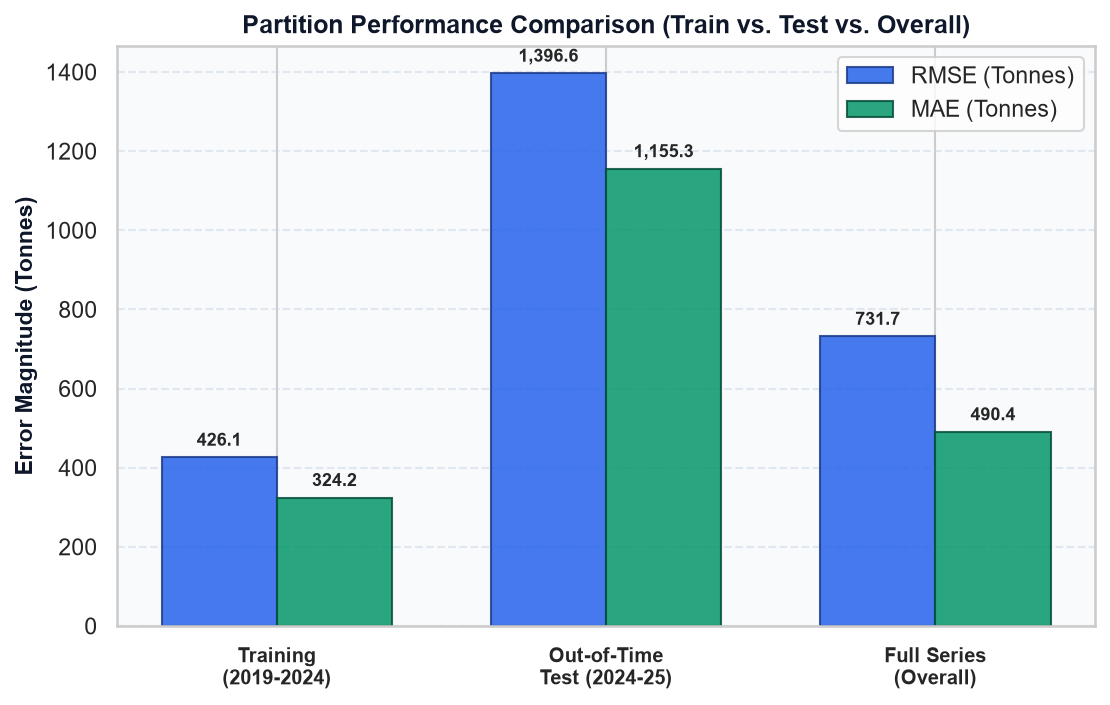

Training Set   -> RMSE: 426.11 t | MAE: 324.20 t
Testing Set    -> RMSE: 1396.62 t | MAE: 1155.28 t
Overall Series -> RMSE: 731.69 t | MAE: 490.41 t


In [13]:
# Cell 8.6: Partition Error Comparison
fig_part, ax_p = plt.subplots(figsize=(7.5, 4.8), dpi=150)
fig_part.patch.set_facecolor('#FFFFFF')
ax_p.set_facecolor('#F8FAFC')

splits_labels = ['Training\n(2019-2024)', 'Out-of-Time\nTest (2024-25)', 'Full Series\n(Overall)']
x_pos = np.arange(len(splits_labels))
b_width = 0.35

train_rmse = np.sqrt(mean_squared_error(y_train, best_model.predict(X_train_scaled)))
train_mae = mean_absolute_error(y_train, best_model.predict(X_train_scaled))
test_rmse = np.sqrt(mean_squared_error(y_test, best_model.predict(X_test_scaled)))
test_mae = mean_absolute_error(y_test, best_model.predict(X_test_scaled))
overall_rmse = np.sqrt(mean_squared_error(y, y_all_pred))
overall_mae = mean_absolute_error(y, y_all_pred)

rmse_p = [train_rmse, test_rmse, overall_rmse]
mae_p = [train_mae, test_mae, overall_mae]

rects_r = ax_p.bar(x_pos - b_width/2, rmse_p, b_width, label='RMSE (Tonnes)', color='#2563EB', edgecolor='#1E3A8A', alpha=0.85)
rects_m = ax_p.bar(x_pos + b_width/2, mae_p, b_width, label='MAE (Tonnes)', color='#059669', edgecolor='#064E3B', alpha=0.85)

ax_p.set_ylabel('Error Magnitude (Tonnes)', fontweight='bold', fontsize=11, color='#0F172A')
ax_p.set_title('Partition Performance Comparison (Train vs. Test vs. Overall)', fontweight='bold', fontsize=12, color='#0F172A')
ax_p.set_xticks(x_pos)
ax_p.set_xticklabels(splits_labels, fontsize=9.5, fontweight='600')
ax_p.grid(axis='y', linestyle='--', alpha=0.5, color='#CBD5E1')
ax_p.legend(frameon=True, facecolor='#FFFFFF', loc='upper right')

for r in rects_r:
    h = r.get_height()
    ax_p.text(r.get_x() + r.get_width()/2., h + 20, f'{h:,.1f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for r in rects_m:
    h = r.get_height()
    ax_p.text(r.get_x() + r.get_width()/2., h + 20, f'{h:,.1f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Training Set   -> RMSE: {train_rmse:.2f} t | MAE: {train_mae:.2f} t')
print(f'Testing Set    -> RMSE: {test_rmse:.2f} t | MAE: {test_mae:.2f} t')
print(f'Overall Series -> RMSE: {overall_rmse:.2f} t | MAE: {overall_mae:.2f} t')

## Cell 8.7: Chronological Forecast Precision Timeline (Monthly MAPE %)
Plots the absolute percentage error $|y_t - \hat{y}_t| / y_t \times 100\%$ across all historical observations against the acceptable 5% municipal tolerance threshold.

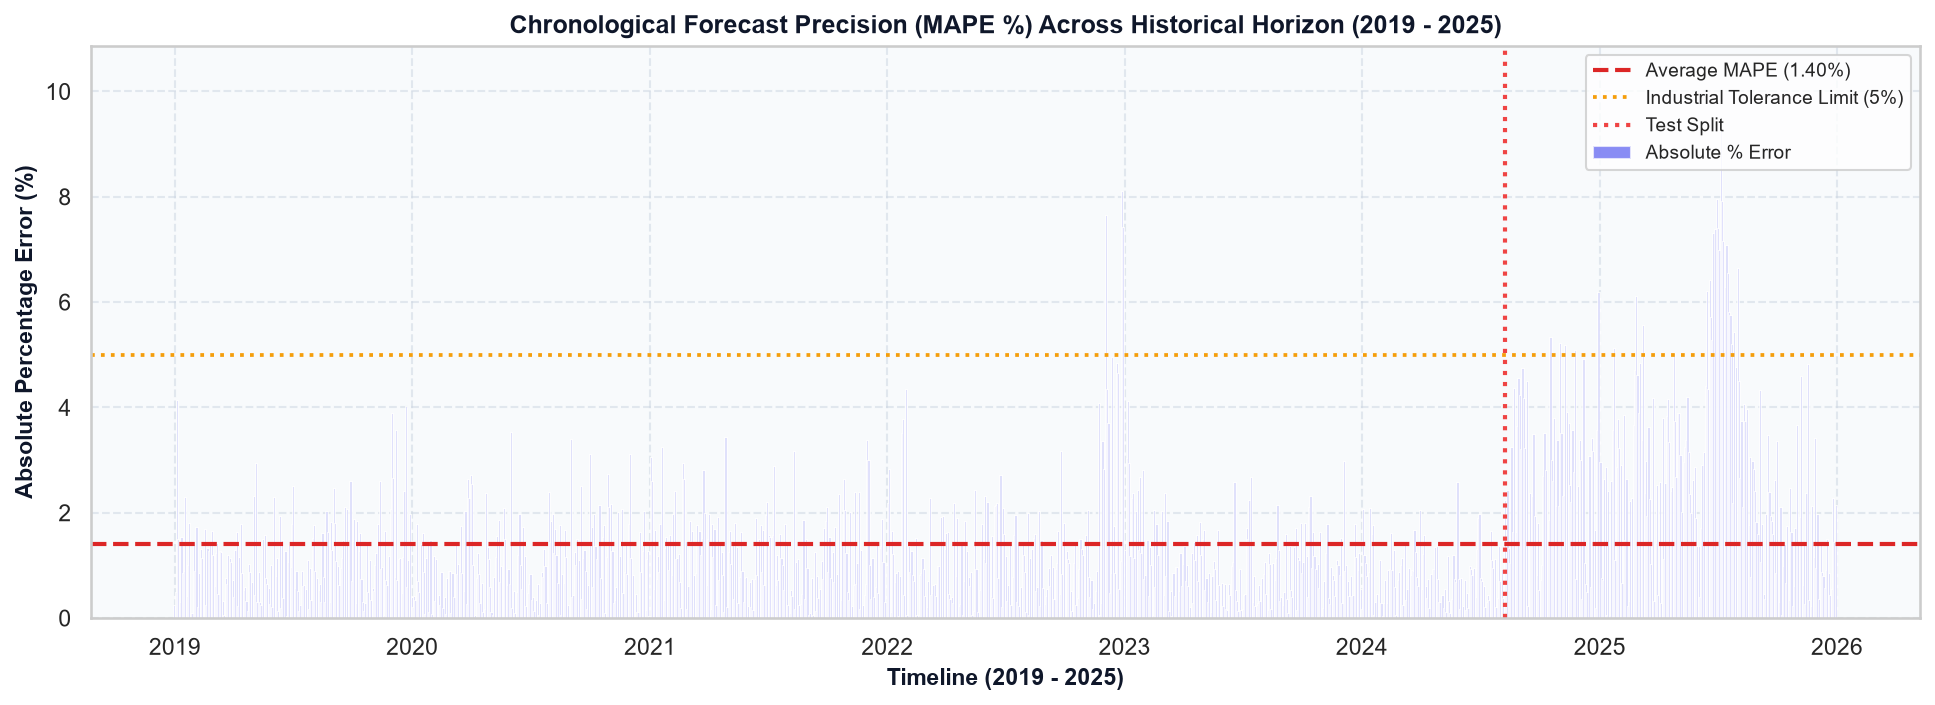

Observations Within 5% Error Tolerance: 97.3%
Average Historical MAPE:                1.40%


In [14]:
# Cell 8.7: Chronological Percentage Error Timeline
abs_pct_errors = np.abs((y - y_all_pred) / y) * 100.0

fig_err_time, ax_et = plt.subplots(figsize=(13, 4.8), dpi=150)
fig_err_time.patch.set_facecolor('#FFFFFF')
ax_et.set_facecolor('#F8FAFC')

ax_et.bar(df['date'], abs_pct_errors, width=1.8, color='#6366F1', alpha=0.75, label='Absolute % Error')
ax_et.axhline(abs_pct_errors.mean(), color='#DC2626', linestyle='--', lw=2, label=f'Average MAPE ({abs_pct_errors.mean():.2f}%)')
ax_et.axhline(5.0, color='#F59E0B', linestyle=':', lw=1.8, label='Industrial Tolerance Limit (5%)')
ax_et.axvline(df['date'].iloc[split_idx], color='#EF4444', linestyle=':', lw=2, label='Test Split')

ax_et.set_ylabel('Absolute Percentage Error (%)', fontweight='bold', fontsize=11, color='#0F172A')
ax_et.set_xlabel('Timeline (2019 - 2025)', fontweight='bold', fontsize=11, color='#0F172A')
ax_et.set_title('Chronological Forecast Precision (MAPE %) Across Historical Horizon (2019 - 2025)', fontweight='bold', fontsize=12, color='#0F172A')
ax_et.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_et.xaxis.set_major_locator(mdates.YearLocator(1))
ax_et.set_ylim(0, max(abs_pct_errors.max() + 1.5, 6.0))
ax_et.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
ax_et.legend(loc='upper right', frameon=True, facecolor='#FFFFFF', fontsize=9)

plt.tight_layout()
plt.show()

print(f'Observations Within 5% Error Tolerance: {np.mean(abs_pct_errors <= 5.0) * 100:.1f}%')
print(f'Average Historical MAPE:                {abs_pct_errors.mean():.2f}%')

## Cell 8.8: Uyo Municipal Zonal Waste Allocation & Fleet Logistics (Section 4.C)
Spatial proportion of municipal solid waste generation across Uyo's six administrative and commercial collection zones, providing actionable compactor fleet routing sizing for AKSEPWMA.

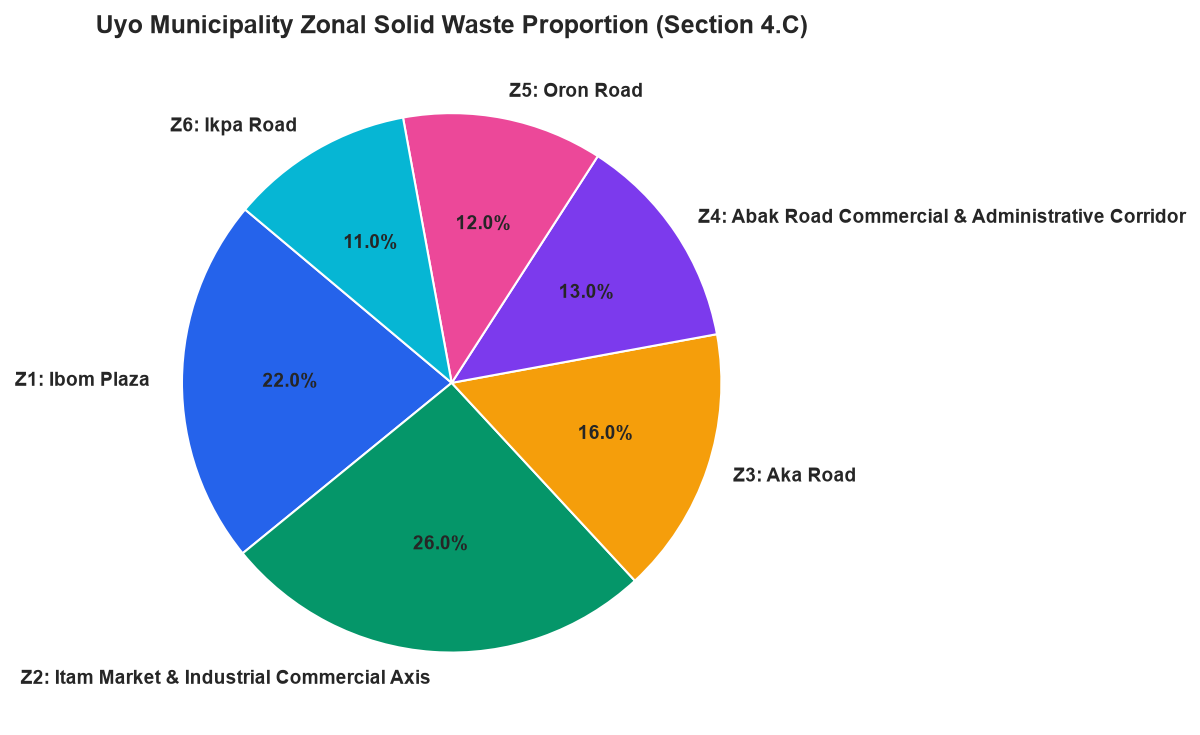

,Zone Code,Collection Zone & Landmark,Dominant Land Use,Generation Share (%),Clearance Frequency,Base 15-Tonne Compactors
0,Z1,Ibom Plaza / Central Business District,High Commercial,22.0,2x Daily,7
1,Z2,Itam Market & Industrial Commercial Axis,Bulk Commercial / Organic,26.0,2x Daily (Continuous),8
2,Z3,Aka Road / Shelter Afrique Residential Corridor,High Residential,16.0,Daily,5
3,Z4,Abak Road Commercial & Administrative Corridor,Institutional / Commercial,13.0,Daily,4
4,Z5,Oron Road / Ring Road Expansion Corridor,Rapid Expansion,12.0,Daily,4
5,Z6,Ikpa Road / Uniuyo Campus Corridor,Institutional / Student,11.0,Daily,3


In [15]:
# Cell 8.8: Uyo Zonal Waste Allocation & Logistics
uyo_zones_data = [
    {'zone_id': 'Z1', 'zone_name': 'Ibom Plaza / Central Business District', 'type': 'High Commercial', 'share_pct': 22.0, 'trucks_base': 7, 'freq': '2x Daily'},
    {'zone_id': 'Z2', 'zone_name': 'Itam Market & Industrial Commercial Axis', 'type': 'Bulk Commercial / Organic', 'share_pct': 26.0, 'trucks_base': 8, 'freq': '2x Daily (Continuous)'},
    {'zone_id': 'Z3', 'zone_name': 'Aka Road / Shelter Afrique Residential Corridor', 'type': 'High Residential', 'share_pct': 16.0, 'trucks_base': 5, 'freq': 'Daily'},
    {'zone_id': 'Z4', 'zone_name': 'Abak Road Commercial & Administrative Corridor', 'type': 'Institutional / Commercial', 'share_pct': 13.0, 'trucks_base': 4, 'freq': 'Daily'},
    {'zone_id': 'Z5', 'zone_name': 'Oron Road / Ring Road Expansion Corridor', 'type': 'Rapid Expansion', 'share_pct': 12.0, 'trucks_base': 4, 'freq': 'Daily'},
    {'zone_id': 'Z6', 'zone_name': 'Ikpa Road / Uniuyo Campus Corridor', 'type': 'Institutional / Student', 'share_pct': 11.0, 'trucks_base': 3, 'freq': 'Daily'}
]
df_zones = pd.DataFrame(uyo_zones_data)

fig_pie, ax_pie = plt.subplots(figsize=(7, 5), dpi=150)
fig_pie.patch.set_facecolor('#FFFFFF')
colors_z = ['#2563EB', '#059669', '#F59E0B', '#7C3AED', '#EC4899', '#06B6D4']
ax_pie.pie(
    df_zones['share_pct'],
    labels=df_zones['zone_id'] + ': ' + df_zones['zone_name'].str.split('/').str[0],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_z,
    textprops={'fontsize': 9, 'weight': 'bold'}
)
ax_pie.set_title('Uyo Municipality Zonal Solid Waste Proportion (Section 4.C)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

display(df_zones[['zone_id', 'zone_name', 'type', 'share_pct', 'freq', 'trucks_base']].rename(columns={
    'zone_id': 'Zone Code',
    'zone_name': 'Collection Zone & Landmark',
    'type': 'Dominant Land Use',
    'share_pct': 'Generation Share (%)',
    'freq': 'Clearance Frequency',
    'trucks_base': 'Base 15-Tonne Compactors'
}))

## Cell 9: Model Retraining on Full 1,200-Observation Dataset & 2026-2030 Projections (Steps 11 - 14)
Retrain the optimal Proposed Composite GPR model on the complete **1,200-observation empirical dataset** (2019-2025) and generate prospective monthly forecasts for Uyo Municipality through 2030 with 95% Bayesian Confidence Intervals.

C:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- 5-Year Municipal Waste Projections (2026 - 2030) ---


,year,Annual_Total,Monthly_Mean,Daily_Mean,Lower_95_CI,Upper_95_CI,Active_Compactors
0,2026,"526,607.7 t","43,884.0 t","1,442.8 t/d","40,480.1 t","47,287.8 t",49 Trucks
1,2027,"528,716.2 t","44,059.7 t","1,448.5 t/d","38,288.2 t","49,831.2 t",49 Trucks
2,2028,"523,100.2 t","43,591.7 t","1,433.1 t/d","35,544.8 t","51,638.6 t",48 Trucks
3,2029,"512,846.4 t","42,737.2 t","1,405.1 t/d","32,672.9 t","52,801.5 t",47 Trucks
4,2030,"500,345.3 t","41,695.4 t","1,370.8 t/d","29,888.8 t","53,502.1 t",46 Trucks



--- Option D Presentation: Next 12 Months (2026) Forecasts with Assigned Waste Classes ---


,Forecast Period,Predicted Waste (Tonnes/Mo),Daily Waste (Tonnes/Day),Waste Generation Class,Lower 95% Limit,Upper 95% Limit,15T Compactor Trucks
0,January 2026,"43,445.8","1,428.4",High,"39,947.1","46,944.5",48
1,February 2026,"43,559.7","1,432.1",High,"40,223.7","46,895.6",48
2,March 2026,"43,931.0","1,444.3",High,"40,715.5","47,146.6",49
3,April 2026,"43,890.1","1,443.0",High,"40,671.5","47,108.7",49
4,May 2026,"43,655.6","1,435.3",High,"40,396.3","46,914.9",48
5,June 2026,"44,361.2","1,458.4",High,"41,191.1","47,531.3",49
6,July 2026,"44,775.3","1,472.1",High,"41,676.3","47,874.2",50
7,August 2026,"44,079.7","1,449.2",High,"40,899.9","47,259.5",49
8,September 2026,"43,578.9","1,432.7",High,"40,183.7","46,974.0",48
9,October 2026,"43,677.9","1,436.0",High,"40,541.0","46,814.7",48


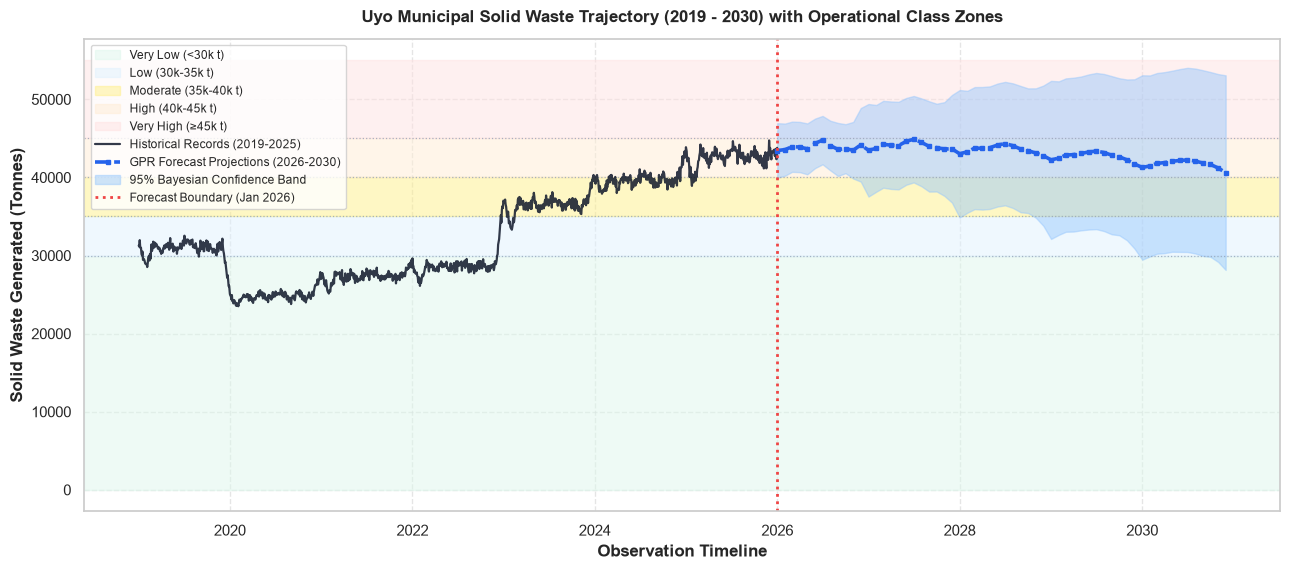

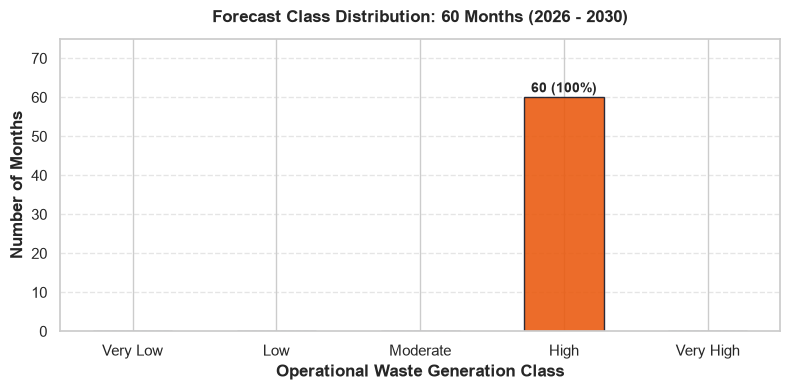

In [16]:
# Cell 9: Future Forecasting
sub_full_idx = np.arange(0, len(X), 6)
sub_full_gpr = GaussianProcessRegressor(
    kernel=candidate_kernels[best_name],
    normalize_y=True,
    alpha=1e-3,
    n_restarts_optimizer=3,
    random_state=42
)
final_scaler = StandardScaler()
X_full_scaled = final_scaler.fit_transform(X)
sub_full_gpr.fit(X_full_scaled[sub_full_idx], y[sub_full_idx])

final_gpr = GaussianProcessRegressor(
    kernel=sub_full_gpr.kernel_,
    optimizer=None,
    normalize_y=True,
    alpha=1e-3,
    random_state=42
)
final_gpr.fit(X_full_scaled, y)

# Construct 2026-2030 Future Dates
future_dates = pd.date_range(start='2026-01-01', end='2030-12-01', freq='MS')
future_df = pd.DataFrame({'date': future_dates})
future_df['year'] = future_df['date'].dt.year
future_df['month'] = future_df['date'].dt.month
future_df['time_index'] = (future_df['year'] - 2019) * 12.0 + (future_df['month'] - 1)
future_df['sin_month'] = np.sin(2 * np.pi * future_df['month'] / 12.0)
future_df['cos_month'] = np.cos(2 * np.pi * future_df['month'] / 12.0)

# Projected Demographic & Climate Features
last_pop = df['population'].iloc[-1]
monthly_growth = (1 + 0.028) ** (1/12) # 2.8% annual population growth
future_df['population'] = [int(round(last_pop * (monthly_growth ** (i + 1)))) for i in range(len(future_df))]

monthly_climate = df.groupby('month')[['avg_temperature_c', 'rainfall_mm', 'humidity_percent']].mean().round(2)
future_df = future_df.merge(monthly_climate, on='month', how='left')

monthly_hols = df.groupby('month')['num_holidays'].median().round().astype(int)
future_df = future_df.merge(monthly_hols, on='month', how='left')

# Execute Bayesian Inference
X_fut_scaled = final_scaler.transform(future_df[feature_cols])
y_fut_pred, y_fut_std = final_gpr.predict(X_fut_scaled, return_std=True)

future_df['forecast_tonnes'] = y_fut_pred
future_df['daily_tonnes'] = y_fut_pred / 30.4167
future_df['ci_lower_95'] = y_fut_pred - 1.96 * y_fut_std
future_df['ci_upper_95'] = y_fut_pred + 1.96 * y_fut_std
future_df['uncertainty_std'] = y_fut_std

# Option D: 5-Tier Empirical Waste Classification System
def classify_waste_5tier(val):
    if val < 30000:
        return 'Very Low'
    elif val < 35000:
        return 'Low'
    elif val < 40000:
        return 'Moderate'
    elif val < 45000:
        return 'High'
    else:
        return 'Very High'

future_df['waste_class'] = future_df['forecast_tonnes'].apply(classify_waste_5tier)
future_df['compactor_trucks'] = np.ceil(future_df['daily_tonnes'] / 30.0).astype(int)

# Annual Summary Table
annual_proj = future_df.groupby('year').agg(
    Annual_Total=('forecast_tonnes', 'sum'),
    Monthly_Mean=('forecast_tonnes', 'mean'),
    Daily_Mean=('daily_tonnes', 'mean'),
    Lower_95_CI=('ci_lower_95', 'mean'),
    Upper_95_CI=('ci_upper_95', 'mean'),
    Active_Compactors=('compactor_trucks', 'mean')
).reset_index()

print('--- 5-Year Municipal Waste Projections (2026 - 2030) ---')
display(annual_proj.style.format({
    'Annual_Total': '{:,.1f} t',
    'Monthly_Mean': '{:,.1f} t',
    'Daily_Mean': '{:,.1f} t/d',
    'Lower_95_CI': '{:,.1f} t',
    'Upper_95_CI': '{:,.1f} t',
    'Active_Compactors': '{:.0f} Trucks'
}))

# Sample Option D Monthly Forecasts (First 12 Months)
print('\n--- Option D Presentation: Next 12 Months (2026) Forecasts with Assigned Waste Classes ---')
disp_sample = future_df.iloc[:12][['date', 'forecast_tonnes', 'daily_tonnes', 'waste_class', 'ci_lower_95', 'ci_upper_95', 'compactor_trucks']].copy()
disp_sample['date'] = disp_sample['date'].dt.strftime('%B %Y')
display(disp_sample.rename(columns={
    'date': 'Forecast Period',
    'forecast_tonnes': 'Predicted Waste (Tonnes/Mo)',
    'daily_tonnes': 'Daily Waste (Tonnes/Day)',
    'waste_class': 'Waste Generation Class',
    'ci_lower_95': 'Lower 95% Limit',
    'ci_upper_95': 'Upper 95% Limit',
    'compactor_trucks': '15T Compactor Trucks'
}).style.format({
    'Predicted Waste (Tonnes/Mo)': '{:,.1f}',
    'Daily Waste (Tonnes/Day)': '{:,.1f}',
    'Lower 95% Limit': '{:,.1f}',
    'Upper 95% Limit': '{:,.1f}'
}))

# Visual 1: Main Forecast Trajectory with Horizontal Class Bands
plt.figure(figsize=(13, 5.8))
plt.axhspan(0, 30000, color='#DEF7EC', alpha=0.5, label='Very Low (<30k t)')
plt.axhspan(30000, 35000, color='#E0F2FE', alpha=0.5, label='Low (30k-35k t)')
plt.axhspan(35000, 40000, color='#FEF08A', alpha=0.5, label='Moderate (35k-40k t)')
plt.axhspan(40000, 45000, color='#FFEDD5', alpha=0.5, label='High (40k-45k t)')
plt.axhspan(45000, 55000, color='#FEE2E2', alpha=0.5, label='Very High (≥45k t)')
for th in [30000, 35000, 40000, 45000]:
    plt.axhline(th, color='#94A3B8', linestyle=':', lw=0.9, alpha=0.8)
plt.plot(df['date'], df['waste_tonnes_estimated'], color='#0F172A', lw=1.6, alpha=0.85, label='Historical Records (2019-2025)')
plt.plot(future_df['date'], future_df['forecast_tonnes'], color='#2563EB', lw=2.6, linestyle='--', marker='s', markersize=3.5, label='GPR Forecast Projections (2026-2030)')
plt.fill_between(future_df['date'], future_df['ci_lower_95'], future_df['ci_upper_95'], color='#93C5FD', alpha=0.45, label='95% Bayesian Confidence Band')
plt.axvline(pd.to_datetime('2026-01-01'), color='#EF4444', linestyle=':', lw=2, label='Forecast Boundary (Jan 2026)')
plt.title('Uyo Municipal Solid Waste Trajectory (2019 - 2030) with Operational Class Zones', fontweight='bold', fontsize=12, pad=12)
plt.ylabel('Solid Waste Generated (Tonnes)', fontweight='bold')
plt.xlabel('Observation Timeline', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True, fontsize=8.8)
plt.tight_layout()
plt.show()

# Visual 2: Forecast Class Distribution Breakdown
plt.figure(figsize=(8, 4))
dist_counts = future_df['waste_class'].value_counts().reindex(['Very Low', 'Low', 'Moderate', 'High', 'Very High'], fill_value=0)
dist_colors = ['#059669', '#0284C7', '#D97706', '#EA580C', '#DC2626']
b_dist = plt.bar(dist_counts.index, dist_counts.values, color=dist_colors, edgecolor='#0F172A', alpha=0.88, width=0.55)
plt.title('Forecast Class Distribution: 60 Months (2026 - 2030)', fontweight='bold', fontsize=12, pad=12)
plt.ylabel('Number of Months', fontweight='bold')
plt.xlabel('Operational Waste Generation Class', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
for b in b_dist:
    h = b.get_height()
    if h > 0:
        pct = (h / len(future_df)) * 100.0
        plt.text(b.get_x() + b.get_width()/2., h + 0.5, f'{h} ({pct:.0f}%)', ha='center', va='bottom', fontweight='bold')
plt.ylim(0, dist_counts.values.max() * 1.25)
plt.tight_layout()
plt.show()

## Cell 10: Model Serialization & Streamlit Artifact Packaging (Step 11 & Step 15)
Save the trained GPR model, standardizer, and evaluated data structures into `gpr_waste_model.pkl` for the Streamlit dashboard.

In [17]:
# Cell 10: Model Serialization
train_res = evaluate_model(y_train, best_model.predict(X_train_scaled), y_train*0.01)
test_res = evaluate_model(y_test, best_model.predict(X_test_scaled), y_test*0.01)
overall_res = evaluate_model(y, y_all_pred, y_all_std)

artifacts = {
    'model': final_gpr,
    'scaler': final_scaler,
    'feature_cols': feature_cols,
    'eval_df': eval_df,
    'metrics': {
        'train': train_res,
        'test': test_res,
        'overall': overall_res
    },
    'historical_df': df,
    'future_df': future_df
}

joblib.dump(artifacts, 'gpr_waste_model.pkl')
print("[OK] Successfully saved 'gpr_waste_model.pkl'. Ready for Streamlit deployment.")

[OK] Successfully saved 'gpr_waste_model.pkl'. Ready for Streamlit deployment.


## Cell 11: Launch the Interactive Streamlit Web Application (Step 15)
Run the terminal command below to launch the Streamlit user interface in your web browser:

```bash
streamlit run app.py
```

In [18]:
# Cell 11: Instruction to launch Streamlit dashboard
print("To start the interactive Streamlit dashboard on your computer, open a terminal in this directory and execute:")
print("streamlit run app.py")

To start the interactive Streamlit dashboard on your computer, open a terminal in this directory and execute:
streamlit run app.py
